# Predicción de churn en una entidad financiera

**Curso:** Métodos y Aplicaciones de Analítica II, Maestría en Analítica para la Inteligencia de Negocios, Pontificia Universidad Javeriana.
**Equipo:** Juan Fernando Rengifo y Juan Diego Díaz.

**Ruta del notebook (CRISP-DM).**

| Fase | Pregunta que responde | Secciones |
|---|---|---|
| 1. Comprensión del negocio | ¿Qué decide el banco y cómo se mide? | 1.1 a 1.3 |
| 2. Comprensión de los datos | ¿Son confiables y qué señales traen? | 2.1 a 2.10 |
| 3. Preparación de los datos | ¿Cómo se preparan sin fuga? | 3.1 y 3.2 |
| 4. Modelado | ¿Qué modelo ordena mejor? | 4.1 a 4.7 |
| 5. Evaluación | ¿Funciona con clientes nuevos y paga? | 5.1 a 5.9 |
| 6. Despliegue, monitoreo y control | ¿Cómo se usa y se vigila? | 6.1 a 6.4 |

La lógica reutilizable vive en `src/churn/`; este notebook la orquesta y explica.

## Preparación del entorno

Los imports van juntos y una sola vez. Los parámetros (rutas, semilla, tamaño del test, pliegues) se leen de `src/churn/config.py`, para que notebook, pruebas y scripts usen los mismos valores.

In [1]:
%matplotlib inline
import platform
import random

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from churn import (comparacion, config, datos, evaluacion, exploracion, explicabilidad, features, graficos,
                   graficos_modelado, graficos_negocio, modelos, monitoreo, negocio, produccion, reportes)

# Semillas fijas: la misma corrida produce los mismos resultados en cualquier computador
random.seed(config.SEMILLA)
np.random.seed(config.SEMILLA)

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 120)  # para ver completos los hiperparámetros elegidos

print(f"Python {platform.python_version()} | pandas {pd.__version__} | numpy {np.__version__}")
print(f"SEMILLA = {config.SEMILLA} | TEST_SIZE = {config.TEST_SIZE} | N_PLIEGUES = {config.N_PLIEGUES}")
print(f"Escenarios de capacidad (supuestos): {[f'{k:.0%}' for k in config.ESCENARIOS_CAPACIDAD]}")

Python 3.11.9 | pandas 2.1.4 | numpy 1.26.4
SEMILLA = 42 | TEST_SIZE = 0.2 | N_PLIEGUES = 5
Escenarios de capacidad (supuestos): ['10%', '20%', '30%']


## CRISP-DM Fase 1: Comprensión del negocio

### 1.1 Problema y necesidad

El banco perdió el 15 % de sus clientes activos en un trimestre y creó un programa de beneficios. Necesita saber **a qué clientes ofrecérselo primero**.

### 1.2 Objetivo y pregunta

Estimar, con las variables de 2021, la probabilidad de *churn* (que el cliente se vaya antes del cierre de 2022) y ordenar a los clientes por ella. **Pregunta:** ¿qué modelo ordena mejor y cuántos churners captura el banco si contacta al 10 %, 20 % o 30 % de mayor riesgo?

### 1.3 Métrica y supuestos

Métrica principal: **AUC** (probabilidad de que el modelo asigne más riesgo a un churner que a quien se queda; 0,5 es azar). La accuracy se compara siempre con el baseline de decir que nadie se va. La acompañan precisión y captura por escenario, AUC-PR y calibración. Los porcentajes de contacto son **supuestos**: el caso no informa la capacidad real.

## CRISP-DM Fase 2: Comprensión de los datos

### 2.1 Carga, validación y partición

Con `churn.datos` se carga el Excel sin modificarlo, se valida esquema, calidad y dos identidades contables (si algo falla, el notebook se detiene), se crea el objetivo `churn` y se parte 80 % train y 20 % test, de forma aleatoria y estratificada (el archivo no trae fechas para una partición temporal; 5.8). **El test no se toca hasta la Fase 5.**

#### Carga de los datos crudos

In [2]:
crudo = datos.cargar_datos()
print(f"Archivo: {config.RUTA_DATOS_CRUDOS.relative_to(config.RAIZ).as_posix()} | filas: {crudo.shape[0]:,} | columnas: {crudo.shape[1]}")

Archivo: data/raw/bank_churn.xlsx | filas: 10,127 | columnas: 21


#### Validación de esquema, calidad y coherencia contable

In [3]:
reporte_validacion = datos.validar_datos(crudo, estricto=True)
print(f"Chequeos superados: {reporte_validacion['cumple'].sum()} de {len(reporte_validacion)}")
display(reporte_validacion)

Chequeos superados: 26 de 26


,chequeo,cumple,detalle
0,Columnas esperadas,True,faltan: ninguna; sobran: ninguna
1,Sin valores faltantes,True,0 celdas vacías
2,Sin filas duplicadas,True,0 filas repetidas
3,Identificador único,True,0 clientnum repetidos
4,Categorías válidas en attrition_flag,True,no esperadas: ninguna
5,Categorías válidas en gender,True,no esperadas: ninguna
6,Categorías válidas en education_level,True,no esperadas: ninguna
7,Categorías válidas en marital_status,True,no esperadas: ninguna
8,Categorías válidas en income_category,True,no esperadas: ninguna
9,Categorías válidas en card_category,True,no esperadas: ninguna


#### Limpieza y creación del objetivo binario

In [4]:
limpio = datos.limpiar_datos(crudo)
display(datos.resumen_variables(limpio))

balance = datos.balance_objetivo(limpio)
display(balance)
baseline = balance.loc[0, "proporcion"]
print(f"Baseline trivial (decir que nadie se va): accuracy de {baseline:.2%} sin detectar a ningún churner")

,tipo,valores_distintos,faltantes,ejemplo
customer_age,int64,45,0,45
gender,object,2,0,M
dependent_count,int64,6,0,3
education_level,object,7,0,High School
marital_status,object,4,0,Married
income_category,object,6,0,$60K - $80K
card_category,object,4,0,Blue
months_on_book,int64,44,0,39
total_relationship_count,int64,6,0,5
months_inactive_12_mon,int64,7,0,1


,clase,clientes,proporcion
churn,,,
0,Se queda (Existing Customer),8500,0.8393
1,Se va (Attrited Customer),1627,0.1607


Baseline trivial (decir que nadie se va): accuracy de 83.93% sin detectar a ningún churner


#### Partición estratificada y guardado de los datos procesados

In [5]:
particion = datos.particionar(limpio)
rutas = datos.guardar_procesado(limpio, particion)
display(particion.resumen())
for nombre, ruta in rutas.items():
    print(f"Guardado ({nombre}): {ruta.relative_to(config.RAIZ).as_posix()}")

,clientes,churners,tasa_churn
conjunto,,,
train,8101,1302,0.1607
test,2026,325,0.1604


Guardado (datos): data/processed/bank_churn_limpio.csv
Guardado (particion): data/processed/particion.csv


#### Lectura y decisión

- **Datos confiables:** 10.127 clientes y 21 columnas, sin vacíos ni duplicados. Las identidades contables se cumplen, así que `avg_open_to_buy` no aporta nada nuevo (2.8).
- **Desbalance:** 1.627 churners (16,07 %). Decir "nadie se va" acierta 83,93 % y no sirve: se elige por AUC y métricas de la clase churn, no por accuracy.
- **Partición:** 8.101 en train y 2.026 en test, con churn de 16,07 % y 16,04 %.

#### Base de trabajo del EDA: solo train

Todo el EDA usa los 8.101 clientes de train: decidir mirando el test invalidaría la evaluación final. Cada hallazgo termina en una decisión (resumen en 2.10).

In [6]:
X_eda, y_eda = particion.X_train, particion.y_train
tasa_global = y_eda.mean()
graficos.aplicar_estilo()
print(f"Clientes para el EDA (train): {len(X_eda):,} | tasa de churn: {tasa_global:.2%}")

Clientes para el EDA (train): 8,101 | tasa de churn: 16.07%


### 2.2 Poder de separación de cada variable numérica

Se mide el **AUC univariado** (0,5 es azar; 1, separación perfecta) y la mediana por clase.

,auc_univariada,sentido,mediana_se_queda,mediana_se_va
variable,,,,
total_trans_ct,0.796,"más alto, menos churn",71.000,43.000
total_ct_chng_q4_q1,0.748,"más alto, menos churn",0.721,0.529
avg_utilization_ratio,0.694,"más alto, menos churn",0.212,0.000
total_revolving_bal,0.690,"más alto, menos churn",1376.000,0.000
total_trans_amt,0.679,"más alto, menos churn",4098.000,2323.000
contacts_count_12_mon,0.644,"más alto, más churn",2.000,3.000
months_inactive_12_mon,0.635,"más alto, más churn",2.000,3.000
total_relationship_count,0.621,"más alto, menos churn",4.000,3.000
total_amt_chng_q4_q1,0.580,"más alto, menos churn",0.742,0.698


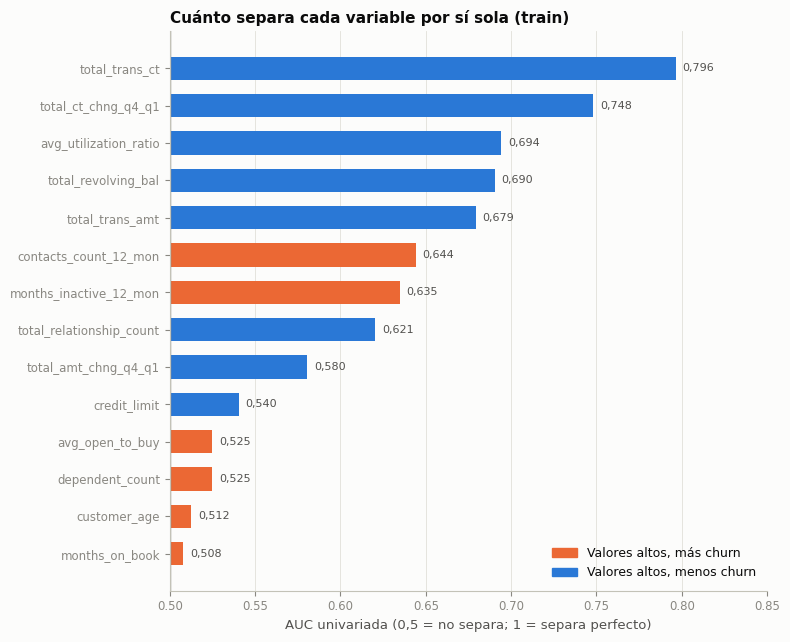

WindowsPath('C:/Users/PERSONAL/Projects/U-Analitica II/Proyecto Final Analitica II/Trabajo Juanfer & Juandi/reports/figures/eda_01_auc_univariada.png')

In [7]:
resumen_num = exploracion.resumen_numericas(X_eda, y_eda)
reportes.guardar_tabla(resumen_num, "eda_resumen_numericas", decimales=3)
display(resumen_num[["auc_univariada", "sentido", "mediana_se_queda", "mediana_se_va"]].round(3))

fig = graficos.barras_auc_univariada(resumen_num, "Cuánto separa cada variable por sí sola (train)")
reportes.mostrar_figura(fig, "eda_01_auc_univariada")

#### Lectura y decisión

- **La actividad concentra la señal:** `total_trans_ct` (0,796) y `total_ct_chng_q4_q1` (0,748) encabezan; el churner típico hace 43 transacciones al año frente a 71 de quien se queda. Las demográficas casi no separan (0,508 a 0,540).

**Decisión.** No se elimina nada por AUC univariado; decide la validación cruzada. Hipótesis: la caída de actividad es la señal de alerta.

### 2.3 Forma de las distribuciones y atípicos

Se revisa la asimetría (cola larga si |asimetría| > 1) y los atípicos por rango intercuartílico.

,asimetria,pct_atipicos_iqr
variable,,
total_ct_chng_q4_q1,2.25,3.91
total_trans_amt,2.05,8.69
total_amt_chng_q4_q1,1.80,3.84
credit_limit,1.68,9.68
avg_open_to_buy,1.68,9.57
avg_utilization_ratio,0.71,0.00
months_inactive_12_mon,0.64,3.27
total_relationship_count,-0.17,0.00
total_revolving_bal,-0.16,0.00


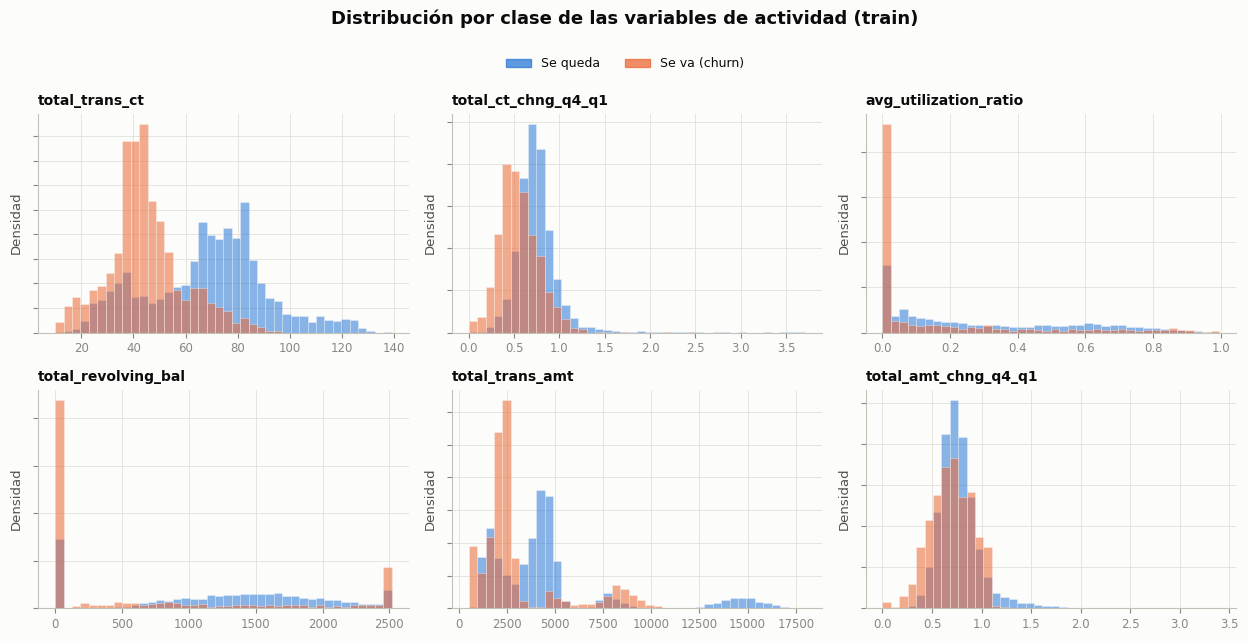

WindowsPath('C:/Users/PERSONAL/Projects/U-Analitica II/Proyecto Final Analitica II/Trabajo Juanfer & Juandi/reports/figures/eda_02_densidades_actividad.png')

In [8]:
display(resumen_num[["asimetria", "pct_atipicos_iqr"]].sort_values("asimetria", key=abs, ascending=False).round(2))

variables_actividad = ["total_trans_ct", "total_ct_chng_q4_q1", "avg_utilization_ratio",
                       "total_revolving_bal", "total_trans_amt", "total_amt_chng_q4_q1"]
fig = graficos.densidades_por_clase(X_eda, y_eda, variables_actividad,
                                    "Distribución por clase de las variables de actividad (train)")
reportes.mostrar_figura(fig, "eda_02_densidades_actividad")

#### Lectura y decisión

- **Colas largas en cinco variables** (asimetría de 1,68 a 2,25) y hasta 9,68 % de atípicos (`credit_limit`). Son reales (pasaron la validación de rangos) y los altos incluyen el segmento sin churners de 2.4.

**Decisión.** No se recortan. Los modelos sensibles a la escala usan Yeo-Johnson y estandarización dentro del pipeline, ajustadas con train; los árboles no lo necesitan.

### 2.4 Monto y número de transacciones

Graficarlas juntas muestra si la frontera es lineal. Los tramos de la tabla son solo descriptivos y no se usan como variables.

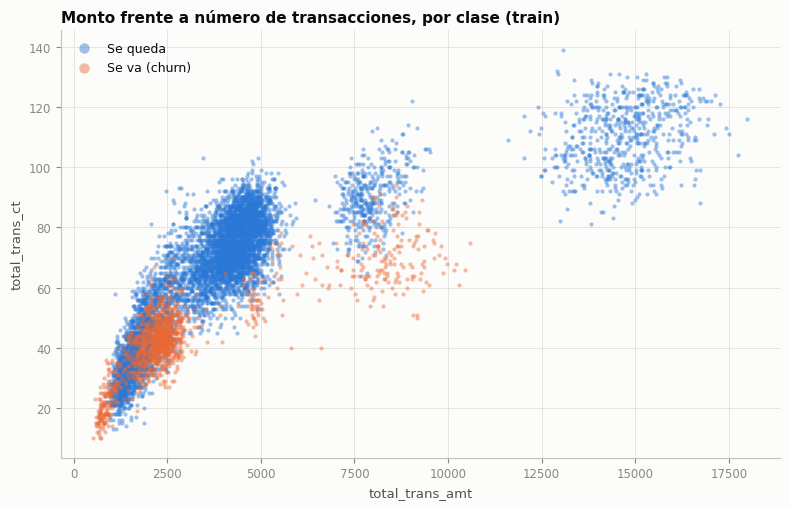

,clientes,churners,tasa_churn,ic95_inf,ic95_sup
tramo_monto,,,,,
hasta 3.000,3149,1041,0.3306,0.3144,0.3472
3.001 a 6.000,3802,88,0.0231,0.0188,0.0284
6.001 a 11.000,554,173,0.3123,0.2751,0.3520
más de 11.000,596,0,0.0000,0.0000,0.0064


AUC univariada del ticket promedio (monto / número de transacciones): 0.509


In [9]:
fig = graficos.dispersion_por_clase(X_eda, y_eda, "total_trans_amt", "total_trans_ct",
                                   "Monto frente a número de transacciones, por clase (train)")
reportes.mostrar_figura(fig, "eda_03_monto_vs_transacciones")

tramo_monto = exploracion.tramos(X_eda["total_trans_amt"], *exploracion.TRAMOS_MONTO)
display(exploracion.tasa_por_nivel(pd.DataFrame({"tramo_monto": tramo_monto}), y_eda, "tramo_monto").round(4))

ticket_promedio = X_eda["total_trans_amt"] / X_eda["total_trans_ct"]
auc_ticket = exploracion.resumen_numericas(pd.DataFrame({"ticket_promedio": ticket_promedio}), y_eda)
print(f"AUC univariada del ticket promedio (monto / número de transacciones): {auc_ticket.iloc[0]['auc_univariada']:.3f}")

#### Lectura y decisión

- **Cuatro segmentos no monótonos:** churn de 33,06 % hasta 3.000, 2,31 % de 3.001 a 6.000, 31,23 % de 6.001 a 11.000 y **0 % sobre 11.000** (0 de 596; IC 95 % de 0 % a 0,64 %).
- **Interacción monto × frecuencia:** en cada segmento los churners transaccionan menos (mediana de 54 frente a 75, y de 69 frente a 90). El ticket promedio separa poco por sí solo (AUC 0,509).

**Decisión.** La frontera no es lineal: se comparan modelos no lineales contra la logística y el ticket promedio entra como candidata (4.1).

### 2.5 Saldo rotativo: dos extremos de riesgo

El saldo rotativo (deuda arrastrada en la tarjeta) mostró picos en los extremos; se mide el churn en cero, en el máximo y en medio.

In [10]:
saldo_maximo = X_eda["total_revolving_bal"].max()
tramo_saldo = exploracion.tramos(
    X_eda["total_revolving_bal"], [-0.5, 0.5, saldo_maximo - 0.5, saldo_maximo + 0.5],
    ["0 (sin saldo)", f"1 a {saldo_maximo - 1:,}".replace(",", "."), f"{saldo_maximo:,} (máximo)".replace(",", ".")])
tabla_saldo = exploracion.tasa_por_nivel(pd.DataFrame({"tramo_saldo": tramo_saldo}), y_eda, "tramo_saldo")
tabla_saldo["pct_clientes"] = 100 * tabla_saldo["clientes"] / len(X_eda)
display(tabla_saldo.round(4))

,clientes,churners,tasa_churn,ic95_inf,ic95_sup,pct_clientes
tramo_saldo,,,,,,
0 (sin saldo),1968,719,0.3653,0.3444,0.3869,24.2933
1 a 2.516,5733,453,0.0790,0.0723,0.0863,70.7690
2.517 (máximo),400,130,0.3250,0.2810,0.3724,4.9377


#### Lectura y decisión

- **Riesgo en U:** 36,53 % de churn sin saldo (24,29 % de train), 32,50 % en el máximo (2.517; 4,94 %) y 7,90 % en medio. Hipótesis: son perfiles distintos, el poco vinculado y el que migra deuda o tiene dificultades.
- Los 400 clientes con exactamente 2.517 sugieren un **tope de registro** (limitación).

**Decisión.** Se prueban las candidatas `saldo_cero` y `saldo_en_maximo` (4.1); los árboles aprenden la U solos.

### 2.6 Relación con el banco

Productos, inactividad, contactos y dependientes: variables discretas, con tasa de churn por valor, **intervalo de confianza de 95 %** (Wilson) y tamaño de cada grupo.

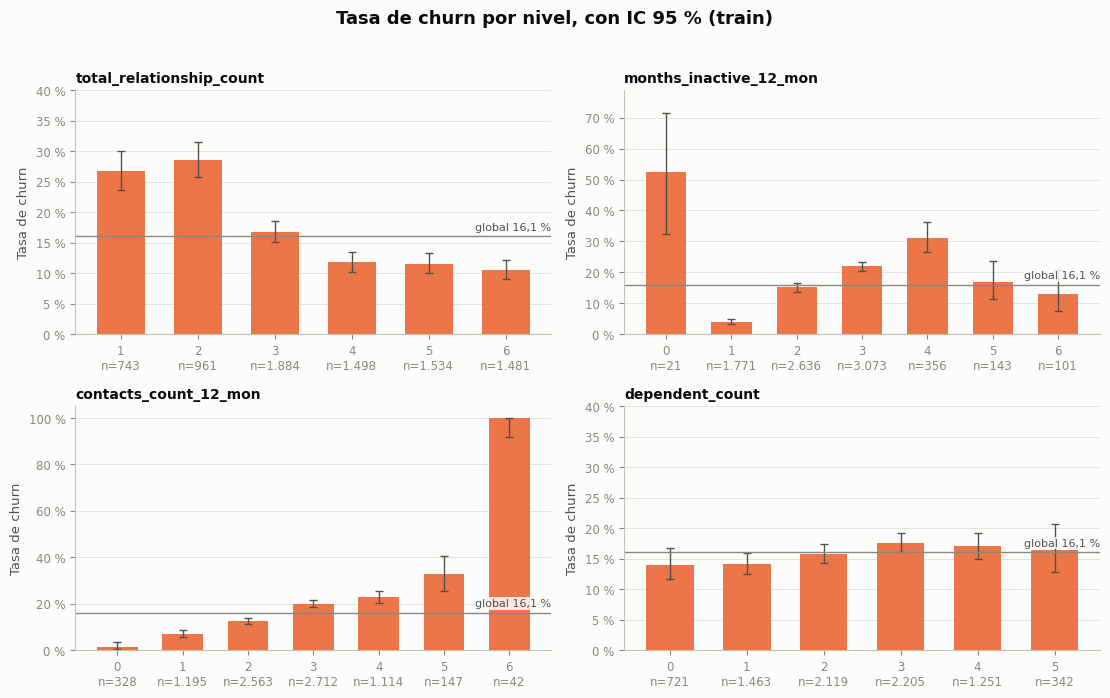

,clientes,churners,tasa_churn,ic95_inf,ic95_sup
contacts_count_12_mon,,,,,
0,328,5,0.0152,0.0065,0.0352
1,1195,85,0.0711,0.0579,0.0871
2,2563,321,0.1252,0.1130,0.1386
3,2712,546,0.2013,0.1867,0.2168
4,1114,255,0.2289,0.2052,0.2545
5,147,48,0.3265,0.2560,0.4059
6,42,42,1.0000,0.9162,1.0000


In [11]:
variables_relacion = ["total_relationship_count", "months_inactive_12_mon",
                      "contacts_count_12_mon", "dependent_count"]
tablas_relacion = {col: exploracion.tasa_por_nivel(X_eda, y_eda, col) for col in variables_relacion}
fig = graficos.tasas_por_nivel(tablas_relacion, tasa_global, "Tasa de churn por nivel, con IC 95 % (train)")
reportes.mostrar_figura(fig, "eda_04_tasas_relacion")
display(tablas_relacion["contacts_count_12_mon"].round(4))

#### Lectura y decisión

- **Más productos, menos churn** (26,78 % con uno frente a 10,53 % a 11,82 % con cuatro a seis); más meses inactivo y más contactos, más churn. Dependientes: casi plano.
- **Los 42 clientes con 6 contactos se fueron todos** (IC 95 % de 91,62 % a 100 %).

**Decisión.** Se conservan como numéricas. Los 6 contactos sugieren una **posible fuga temporal** (contactos del propio retiro): se prueba sin la variable en 5.7.

### 2.7 Variables demográficas y de producto

Para las cinco categóricas se mide la tasa por categoría, el chi cuadrado y la **V de Cramér** (fuerza de 0 a 1; bajo 0,1 es débil).

,categorias,p_valor,v_cramer,categoria_menos_frecuente,clientes_categoria_menos_frecuente
variable,,,,,
gender,2,0.0002,0.0417,M,3829
income_category,6,0.0387,0.0381,$120K +,588
education_level,7,0.2039,0.0324,Doctorate,356
marital_status,4,0.1343,0.0262,Divorced,599
card_category,4,0.5165,0.0168,Platinum,17


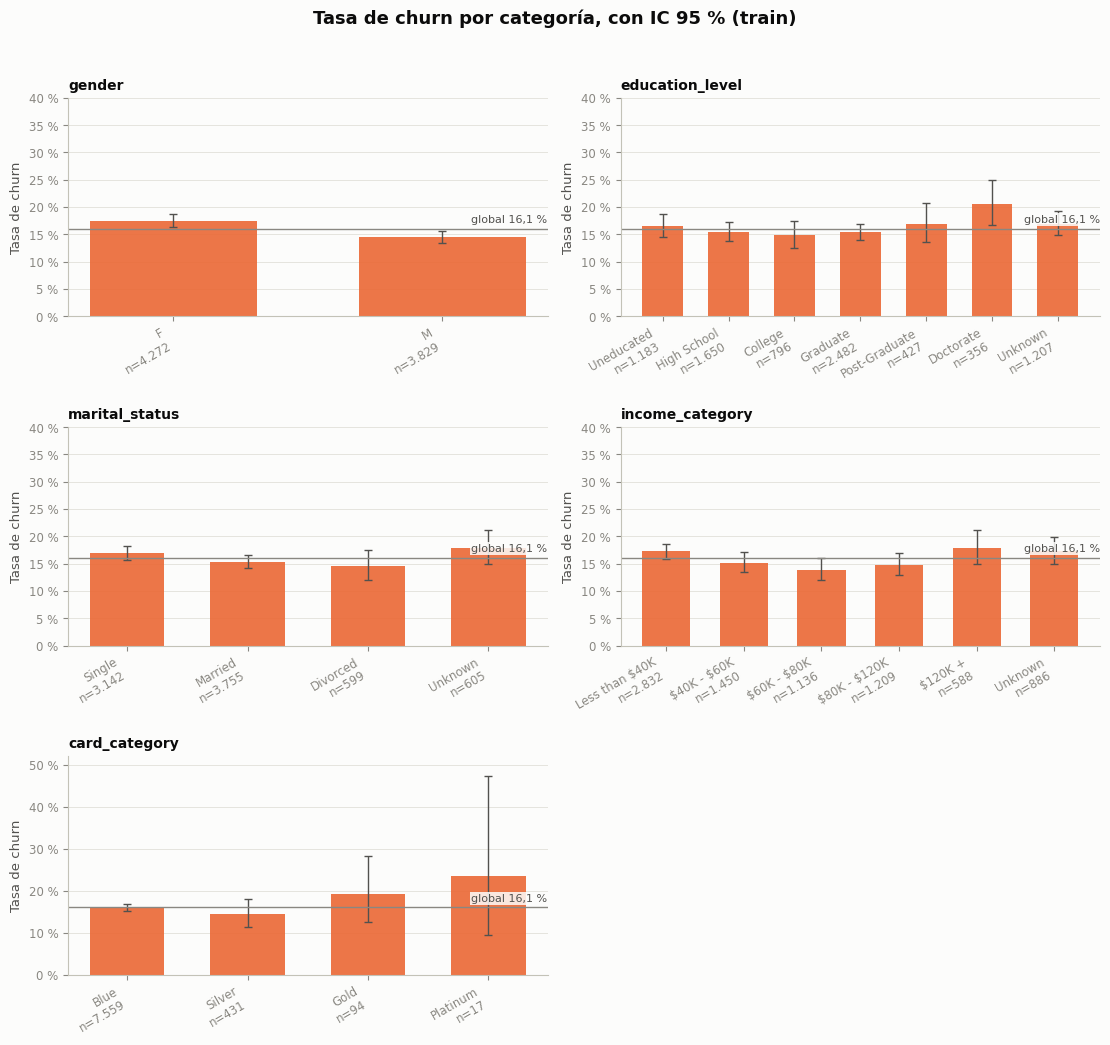

,clientes,churners,tasa_churn,ic95_inf,ic95_sup
card_category,,,,,
Blue,7559,1218,0.1611,0.1530,0.1696
Silver,431,62,0.1439,0.1139,0.1801
Gold,94,18,0.1915,0.1247,0.2825
Platinum,17,4,0.2353,0.0956,0.4726


In [12]:
asociacion = exploracion.asociacion_categoricas(X_eda, y_eda)
reportes.guardar_tabla(asociacion, "eda_asociacion_categoricas", decimales=4)
display(asociacion.round(4))

tablas_categoricas = {col: exploracion.tasa_por_nivel(X_eda, y_eda, col, orden)
                      for col, orden in datos.ORDEN_CATEGORIAS.items()}
fig = graficos.tasas_por_nivel(tablas_categoricas, tasa_global,
                               "Tasa de churn por categoría, con IC 95 % (train)", rotar=True)
reportes.mostrar_figura(fig, "eda_05_tasas_categoricas")
display(tablas_categoricas["card_category"].round(4))

#### Lectura y decisión

- **Asociación débil:** la V de Cramér mayor es la de `gender` (0,042). Solo `gender` (p = 0,0002) e `income_category` (p = 0,039) son significativas: mujeres 17,53 % de churn, hombres 14,44 %.
- Sin gradiente ordenado en educación ni ingresos; `Unknown` (16,98 % a 17,85 %) se parece a la tasa global; Gold (94) y Platinum (17) son muy pequeñas.

**Decisión.** One-Hot para las cinco, `Unknown` como categoría y, dentro del pipeline, agrupar como infrecuentes las de menos de 100 clientes.

### 2.8 Redundancia entre variables

Variables que dicen lo mismo inflan la importancia de un concepto. Se usa Spearman y se rotulan los pares con |r| ≥ 0,5.

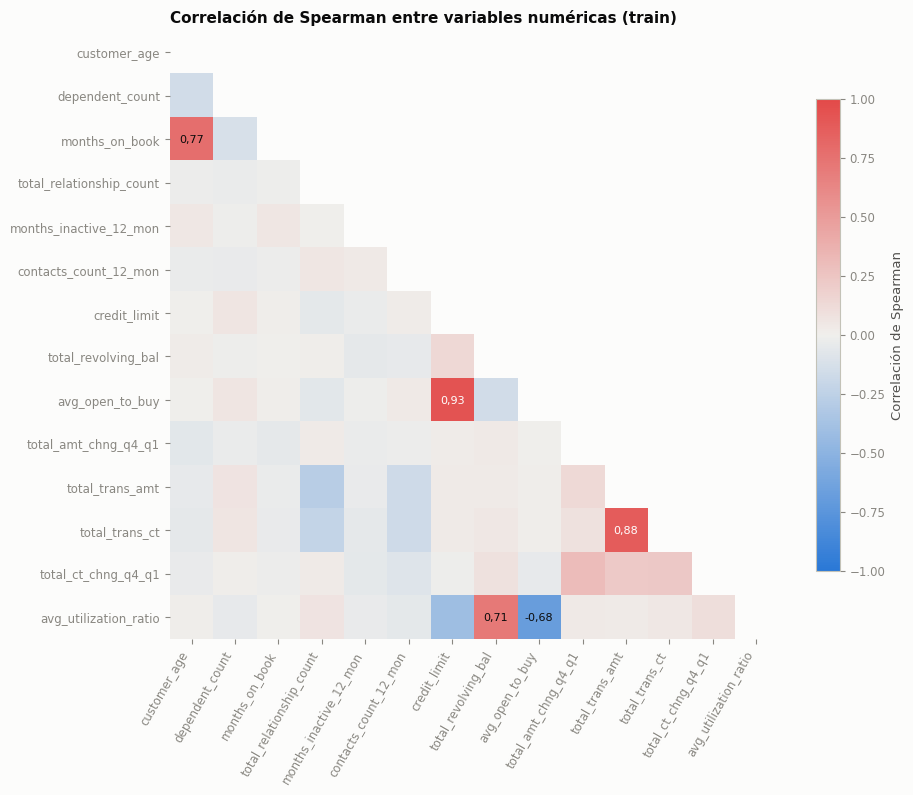

,variable_1,variable_2,correlacion
0,credit_limit,avg_open_to_buy,0.931
1,total_trans_amt,total_trans_ct,0.882
2,customer_age,months_on_book,0.770
3,total_revolving_bal,avg_utilization_ratio,0.709
4,avg_open_to_buy,avg_utilization_ratio,-0.684


In [13]:
corr_spearman = X_eda.select_dtypes("number").corr(method="spearman")
fig = graficos.mapa_correlacion(corr_spearman, "Correlación de Spearman entre variables numéricas (train)")
reportes.mostrar_figura(fig, "eda_06_correlacion")
display(exploracion.pares_correlacionados(X_eda, umbral=0.5).round(3))

#### Lectura y decisión

| Par | Spearman | Decisión |
|---|---|---|
| `credit_limit` y `avg_open_to_buy` | 0,931 | **Se elimina `avg_open_to_buy`** (es `credit_limit` menos `total_revolving_bal`) |
| `total_trans_amt` y `total_trans_ct` | 0,882 | Se conservan: su combinación separa mejor |
| `customer_age` y `months_on_book` | 0,770 | Se conservan: miden cosas distintas |
| `total_revolving_bal` y `avg_utilization_ratio` | 0,709 | Se conservan: la utilización es la versión relativa |
| `avg_open_to_buy` y `avg_utilization_ratio` | -0,684 | Se resuelve al eliminar `avg_open_to_buy` |

### 2.9 Anomalías que limitan la interpretación

Dos patrones parecen efectos de la captura de datos y no comportamiento real: condicionan qué se puede concluir.

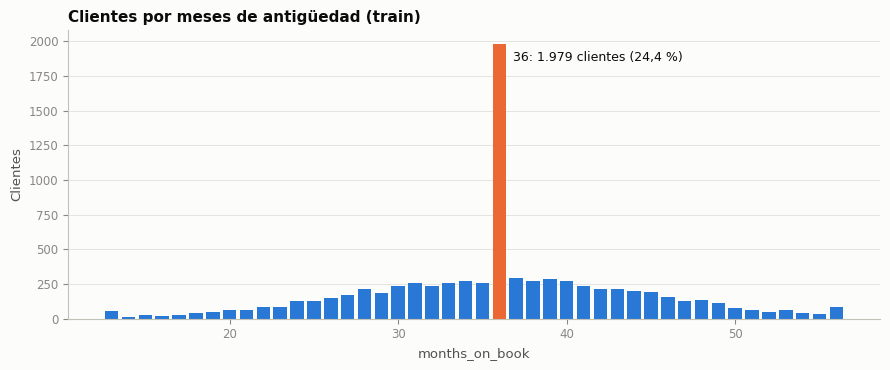

Tasa de churn con 36 meses: 17.48% | resto: 15.62%


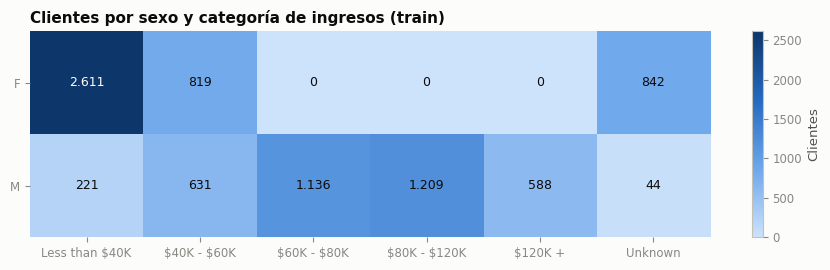

Mujeres en rangos de 60K o más: 0
Proporción de mujeres entre los ingresos Unknown: 95.03%


In [14]:
moda_antiguedad = exploracion.concentracion_moda(X_eda, "months_on_book")
fig = graficos.barras_conteo(X_eda, "months_on_book", moda_antiguedad["valor"],
                             "Clientes por meses de antigüedad (train)")
reportes.mostrar_figura(fig, "eda_07_antiguedad")
es_moda = X_eda["months_on_book"] == moda_antiguedad["valor"]
print(f"Tasa de churn con {moda_antiguedad['valor']} meses: {y_eda[es_moda].mean():.2%} | resto: {y_eda[~es_moda].mean():.2%}")

sexo_ingresos = pd.crosstab(X_eda["gender"], X_eda["income_category"])[datos.ORDEN_CATEGORIAS["income_category"]]
fig = graficos.tabla_cruzada(sexo_ingresos, "Clientes por sexo y categoría de ingresos (train)")
reportes.mostrar_figura(fig, "eda_08_sexo_ingresos")
print(f"Mujeres en rangos de 60K o más: {sexo_ingresos.loc['F', ['$60K - $80K', '$80K - $120K', '$120K +']].sum()}")
print(f"Proporción de mujeres entre los ingresos Unknown: {sexo_ingresos.loc['F', 'Unknown'] / sexo_ingresos['Unknown'].sum():.2%}")

#### Lectura y decisión

- **Pico de 36 meses de antigüedad:** 1.979 clientes (24,43 %) frente a 250 a 300 en los vecinos; probable relleno. Churn de 17,48 % frente a 15,62 % en el resto. Se conserva y se reporta como limitación.
- **Sexo e ingresos no son independientes:** ninguna mujer con 60K o más y 95,03 % de los `Unknown` son mujeres. Sin conclusiones por sexo ni ingresos (5.7).

### 2.10 Resumen de decisiones del EDA

| # | Hallazgo (train) | Decisión | Se aplica en |
|---|---|---|---|
| 1 | 16,07 % de churn; baseline de 83,93 % | Elegir por AUC, no por accuracy | Fases 4 y 5 |
| 2 | La actividad concentra la señal | No eliminar por AUC univariado | 4.5 y 5.6 |
| 3 | Colas largas con atípicos reales | Yeo-Johnson y estandarización en el pipeline | Fase 3 |
| 4 | Monto no monótono e interacción con frecuencia | Modelos no lineales; ticket promedio candidato | 3.1 y 4.1 |
| 5 | Saldo rotativo en U | Candidatas `saldo_cero` y `saldo_en_maximo` | 3.1 y 4.1 |
| 6 | 6 contactos = 100 % de churn | Sensibilidad con y sin `contacts_count_12_mon` | 5.7 |
| 7 | Categóricas débiles y sin orden | One-Hot; `Unknown` propia; infrecuentes agrupadas | Fase 3 |
| 8 | `avg_open_to_buy` es redundante | Eliminarla | Fase 3 |
| 9 | Pico de 36 meses | Conservar y reportar | Informe |
| 10 | Ninguna mujer con 60K o más | Sin conclusiones por sexo; modelo sin `gender` | 5.7 e informe |

## CRISP-DM Fase 3: Preparación de los datos

### 3.1 Pipeline sin fuga

Las decisiones de 2.10 se vuelven código en `churn.features`. Todo paso que aprende de los datos (saldo máximo, categorías frecuentes, Yeo-Johnson, medias) va dentro de un `Pipeline`: cada pliegue lo aprende solo con su parte de entrenamiento y el test nunca influye (**sin fuga de información**).

- `variables`: elimina `avg_open_to_buy` y, opcionalmente, crea `ticket_promedio`, `saldo_cero` y `saldo_en_maximo` (apagadas hasta 4.1).
- `codificador`: One-Hot de las 5 categóricas y, en modelos sensibles a la escala, Yeo-Johnson con estandarización.

Hay dos variantes: **con escalado** (logística, SVM, red neuronal) y **sin escalado** (árboles y ensambles).

#### Dos variantes de preparación ajustadas con train

In [15]:
preparaciones = {
    "con escalado (logística, SVM, red neuronal)": features.construir_preparacion(
        escalar=True, ticket_promedio=True, indicadores_saldo=True),
    "sin escalado (árboles y ensambles)": features.construir_preparacion(
        escalar=False, ticket_promedio=True, indicadores_saldo=True),
}
for nombre, preparacion in preparaciones.items():
    preparacion.fit(particion.X_train)
    print(f"{nombre}: {len(features.nombres_salida(preparacion))} columnas de salida (candidatas activadas para mostrarlas)")

prep_escalada = preparaciones["con escalado (logística, SVM, red neuronal)"]
nombres_salida = features.nombres_salida(prep_escalada)
resumen_prep = features.resumen_preparacion(prep_escalada)
display(resumen_prep["columnas_por_origen"])
print(f"Categorías agrupadas como infrecuentes (menos de {features.MIN_FRECUENCIA_CATEGORIA} clientes en train): {resumen_prep['infrecuentes']}")
print(f"Saldo máximo aprendido de train para saldo_en_maximo: {resumen_prep['saldo_maximo']:,.0f}")

con escalado (logística, SVM, red neuronal): 37 columnas de salida (candidatas activadas para mostrarlas)
sin escalado (árboles y ensambles): 37 columnas de salida (candidatas activadas para mostrarlas)


,columnas
origen,
One-Hot,21
numérica original,13
candidata,3


Categorías agrupadas como infrecuentes (menos de 100 clientes en train): {'card_category': ['Gold', 'Platinum']}
Saldo máximo aprendido de train para saldo_en_maximo: 2,517


#### Lectura y decisión

- **37 columnas** con las candidatas activadas (34 sin ellas): 13 numéricas, 3 candidatas y 21 One-Hot.
- Solo `card_category` tiene categorías bajo 100 clientes (Gold y Platinum quedan juntas). El saldo máximo aprendido es **2.517**, el tope del EDA.

### 3.2 Controles

Dos verificaciones de que la preparación hace lo que dice.

#### Chequeos: train ajusta, test solo transforma

In [16]:
for nombre, preparacion in preparaciones.items():
    print(f"Variante {nombre}:")
    display(features.verificar_preparacion(preparacion, particion.X_train, particion.X_test))

Variante con escalado (logística, SVM, red neuronal):


,chequeo,cumple,detalle
0,Sin faltantes ni infinitos en train,True,"8,101 x 37"
1,Sin faltantes ni infinitos en test,True,"2,026 x 37"
2,avg_open_to_buy no llega al modelo,True,37 columnas de salida
3,Nombres de columna únicos,True,
4,Train estandarizado (media 0),True,máx |media| = 3.9e-15
5,Train estandarizado (desviación 1),True,máx |desv - 1| = 2.2e-16
6,Test transformado con parámetros de train,True,máx |media test| = 0.047 (distinto de 0)


Variante sin escalado (árboles y ensambles):


,chequeo,cumple,detalle
0,Sin faltantes ni infinitos en train,True,"8,101 x 37"
1,Sin faltantes ni infinitos en test,True,"2,026 x 37"
2,avg_open_to_buy no llega al modelo,True,37 columnas de salida
3,Nombres de columna únicos,True,


#### Efecto de Yeo-Johnson sobre la asimetría

In [17]:
antes = prep_escalada.named_steps["variables"].transform(particion.X_train)
despues = pd.DataFrame(prep_escalada.transform(particion.X_train), columns=nombres_salida, index=particion.X_train.index)
variables_cola_larga = ["total_ct_chng_q4_q1", "total_trans_amt", "total_amt_chng_q4_q1", "credit_limit", features.COLUMNA_TICKET]
efecto = pd.DataFrame({"asimetria_antes": antes[variables_cola_larga].skew(),
                       "asimetria_despues": despues[variables_cola_larga].skew()})
display(efecto.round(2))

,asimetria_antes,asimetria_despues
total_ct_chng_q4_q1,2.25,-0.08
total_trans_amt,2.05,0.00
total_amt_chng_q4_q1,1.80,-0.09
credit_limit,1.68,0.10
ticket_promedio,1.90,-0.01


#### Lectura y decisión

- **Sin fuga:** sin faltantes ni infinitos en las dos variantes. Train queda con media 0 y desviación 1 y el test no (hasta 0,047): el test se transforma con parámetros de train.
- **Yeo-Johnson corrige las colas:** la asimetría de las cinco variables pasa de 1,68 a 2,25 a quedar entre -0,09 y 0,10.

**Decisión.** Los pasos entran al pipeline de cada modelo y la validación cruzada decide las candidatas. `tests/test_features.py` verifica que el test no cambia lo aprendido.

## CRISP-DM Fase 4: Modelado

### 4.1 Variables candidatas

Se comparan **ocho modelos** (lineal, SVM, red neuronal, bagging y boosting) con un protocolo único:

- Validación cruzada estratificada de 5 pliegues sobre train, iguales para todos.
- **AUC** para elegir, más AP (AUC-PR de la clase churn; azar = 16 %) y la brecha train frente a CV.
- El desbalance (ninguno, pesos o SMOTE) como un hiperparámetro más.
- Dentro de cada modelo gana el mayor AUC; los candidatos a menos de una desviación empatan y se prefiere la estrategia más simple.

Cada búsqueda se guarda en `models/experimentos/` con una **huella digital** de datos, grilla y versiones de librerías: si nada cambió, se carga (la búsqueda completa tarda cerca de 50 minutos). `REENTRENAR = True` repite todo.

#### Diseño del experimento: catálogo de ocho modelos

In [18]:
REENTRENAR = False  # True: ignora la caché y repite todas las búsquedas
catalogo = modelos.catalogo_modelos()
display(comparacion.tabla_catalogo(catalogo))

,familia,preparacion,estrategias_desbalance,hiperparametros,candidatos,ajustes_cv
modelo,,,,,,
Regresión logística,lineal,con escalado,"ninguna, pesos, SMOTE","C, penalty",30,150
SVM (kernel RBF),kernel,con escalado,"ninguna, pesos, SMOTE","C, gamma",36,180
Red neuronal (MLP),red neuronal,con escalado,"ninguna, SMOTE","hidden_layer_sizes, alpha",24,120
Random Forest,bagging,sin escalado,"ninguna, pesos, SMOTE","max_depth, min_samples_leaf, max_features",24,120
AdaBoost,boosting,sin escalado,"ninguna, SMOTE","estimator__max_depth, n_estimators, learning_rate",24,120
Gradient Boosting,boosting,sin escalado,"ninguna, SMOTE","n_estimators, learning_rate, max_depth",16,80
XGBoost,boosting,sin escalado,"ninguna, pesos, SMOTE","n_estimators, learning_rate, max_depth",24,120
LightGBM,boosting,sin escalado,"ninguna, pesos, SMOTE","n_estimators, learning_rate, num_leaves",24,120


Primero se decide si se quedan las tres candidatas. Cada modelo se evalúa con valores por defecto en las cuatro combinaciones y se mide la **mejora pareada** pliegue a pliegue. **Regla:** se adopta solo si la mejora media es positiva, mayor que su desviación y aparece en al menos 4 de 5 pliegues; si no, parsimonia.

In [19]:
tabla_candidatas = comparacion.experimento_candidatas(catalogo, particion.X_train, particion.y_train)
reportes.guardar_tabla(tabla_candidatas, "modelado_candidatas", indice=False)
mejora, pliegues = comparacion.tablas_candidatas(tabla_candidatas, catalogo)
print("Mejora media de AUC contra la versión base:")
display(mejora.round(4))
print("Pliegues (de 5) en que mejora:")
display(pliegues)

decision_candidatas = comparacion.decidir_candidatas(tabla_candidatas)
display(comparacion.aplicar_decision_candidatas(catalogo, decision_candidatas))

Mejora media de AUC contra la versión base:


combinacion,base,+ ticket,+ saldo,+ ticket + saldo
modelo,,,,
Regresión logística,0.0,0.0050,0.0091,0.0130
SVM (kernel RBF),0.0,0.0038,0.0008,0.0047
Red neuronal (MLP),0.0,-0.0009,0.0005,-0.0002
Random Forest,0.0,0.0017,-0.0000,0.0022
AdaBoost,0.0,0.0007,0.0000,0.0007
Gradient Boosting,0.0,-0.0002,-0.0000,-0.0002
XGBoost,0.0,-0.0005,0.0006,-0.0003
LightGBM,0.0,-0.0002,0.0001,-0.0001


Pliegues (de 5) en que mejora:


combinacion,base,+ ticket,+ saldo,+ ticket + saldo
modelo,,,,
Regresión logística,0,5,5,5
SVM (kernel RBF),0,5,3,5
Red neuronal (MLP),0,3,2,3
Random Forest,0,5,3,5
AdaBoost,0,4,0,4
Gradient Boosting,0,1,2,2
XGBoost,0,2,4,3
LightGBM,0,1,4,3


,ticket_promedio,indicadores_saldo
Regresión logística,True,True
SVM (kernel RBF),True,True
Red neuronal (MLP),False,False
Random Forest,True,True
AdaBoost,False,False
Gradient Boosting,False,False
XGBoost,False,True
LightGBM,False,False


#### Lectura y decisión

- **Ayudan a los modelos sin cortes propios:** logística +0,0130 de AUC, SVM +0,0047 y Random Forest +0,0022, en 5 de 5 pliegues. En boosting y en la red, sin mejora consistente.

**Decisión.** Logística, SVM y Random Forest usan las tres candidatas; el resto, la versión base, salvo XGBoost, que adopta las de saldo por un margen mínimo (+0,0006 frente a una variación de 0,0005). Ese margen se invierte entre sistemas operativos: las cifras de XGBoost son las de la ejecución en Windows; LightGBM, el modelo final, no cambia.

### 4.2 Ronda 1: búsqueda de hiperparámetros

`GridSearchCV` recorre la grilla de cada modelo con las tres estrategias de desbalance y elige la mejor combinación por AUC de validación cruzada.

In [20]:
ronda_1 = comparacion.entrenar_o_cargar(catalogo, particion.X_train, particion.y_train,
                                        config.RUTA_EXPERIMENTOS, "ronda_1", reentrenar=REENTRENAR)
columnas_tabla = ["familia", "auc_cv", "auc_cv_desv", "ap_cv", "auc_train", "brecha_train_cv",
                  "tiempo_ajuste_s", "candidatos", "estrategia", "mejores_hiperparametros"]
display(ronda_1.tabla_cv()[columnas_tabla].round(4))

print("Mejor AUC de CV por estrategia de desbalance:")
tabla_estrategias = comparacion.auc_por_estrategia(ronda_1)
reportes.guardar_tabla(tabla_estrategias, "modelado_estrategias")
display(tabla_estrategias.round(4))

   1/8 Regresión logística: 30 candidatos x 5 pliegues... AUC CV 0.9510 (18 s)
   2/8 SVM (kernel RBF): 36 candidatos x 5 pliegues... AUC CV 0.9739 (155 s)
   3/8 Red neuronal (MLP): 24 candidatos x 5 pliegues... AUC CV 0.9684 (69 s)
   4/8 Random Forest: 24 candidatos x 5 pliegues... AUC CV 0.9894 (161 s)
   5/8 AdaBoost: 24 candidatos x 5 pliegues... AUC CV 0.9920 (309 s)
   6/8 Gradient Boosting: 16 candidatos x 5 pliegues... AUC CV 0.9929 (130 s)
   7/8 XGBoost: 24 candidatos x 5 pliegues... AUC CV 0.9935 (33 s)
   8/8 LightGBM: 24 candidatos x 5 pliegues... AUC CV 0.9941 (36 s)


,familia,auc_cv,auc_cv_desv,ap_cv,auc_train,brecha_train_cv,tiempo_ajuste_s,candidatos,estrategia,mejores_hiperparametros
modelo,,,,,,,,,,
LightGBM,boosting,0.9941,0.0013,0.9730,1.0000,0.0059,2.8735,24,ninguna,"{'learning_rate': 0.03, 'n_estimators': 600, 'num_leaves': 31}"
XGBoost,boosting,0.9935,0.0017,0.9712,1.0000,0.0065,3.2281,24,ninguna,"{'learning_rate': 0.03, 'max_depth': 5, 'n_estimators': 600}"
Gradient Boosting,boosting,0.9929,0.0019,0.9691,1.0000,0.0070,16.5125,16,ninguna,"{'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 400}"
AdaBoost,boosting,0.9920,0.0023,0.9660,0.9998,0.0078,30.3024,24,ninguna,"{'estimator__max_depth': 2, 'learning_rate': 1.0, 'n_estimators': 600}"
Random Forest,bagging,0.9894,0.0024,0.9525,1.0000,0.0105,16.1378,24,ninguna,"{'max_depth': 12, 'max_features': 0.5, 'min_samples_leaf': 1}"
SVM (kernel RBF),kernel,0.9739,0.0028,0.8971,0.9962,0.0223,4.8843,36,ninguna,"{'C': 1, 'gamma': 0.1}"
Red neuronal (MLP),red neuronal,0.9684,0.0031,0.8884,0.9862,0.0179,5.4499,24,ninguna,"{'alpha': 0.001, 'hidden_layer_sizes': (64, 32)}"
Regresión logística,lineal,0.9510,0.0018,0.8365,0.9538,0.0027,1.9147,30,ninguna,"{'C': 1, 'penalty': 'l1'}"


Mejor AUC de CV por estrategia de desbalance:


estrategia,ninguna,pesos,SMOTE,rango_entre_estrategias,desv_mejor_candidato
Regresión logística,0.9510,0.9510,0.9505,0.0006,0.0018
SVM (kernel RBF),0.9739,0.9745,0.9742,0.0006,0.0028
Red neuronal (MLP),0.9684,NaN,0.9699,0.0015,0.0031
Random Forest,0.9894,0.9902,0.9885,0.0017,0.0024
AdaBoost,0.9920,NaN,0.9918,0.0002,0.0023
Gradient Boosting,0.9929,NaN,0.9931,0.0002,0.0019
XGBoost,0.9935,0.9936,0.9936,0.0001,0.0017
LightGBM,0.9941,0.9940,0.9942,0.0002,0.0013


#### Lectura y decisión

- **LightGBM encabeza** (AUC de CV 0,9941) y la logística cierra (0,9510); el AP separa más (0,9730 frente a 0,8365).
- **El desbalance casi no cambia el AUC** (de 0,0001 a 0,0017 entre estrategias, bajo la desviación): los ocho quedaron con "ninguna". El AUC solo mide el orden; el desbalance se trata al elegir cuántos contactar (5.4). SMOTE se aplicó después del One-Hot, así que crea valores intermedios en las columnas categóricas (lo correcto sería SMOTENC); no cambia nada porque no se eligió en ningún modelo.
- **Brecha train-CV:** de 0,0059 a 0,0078 en boosting y hasta 0,0223 en SVM. La logística casi no tiene (0,0027) pero es la más baja: **alto sesgo**.

### 4.3 Efecto de los hiperparámetros y óptimos en el borde

Se grafica el mejor AUC con cada valor del hiperparámetro principal y se listan los que quedaron en un **extremo de la grilla**: allí el mejor valor podría estar fuera de lo probado.

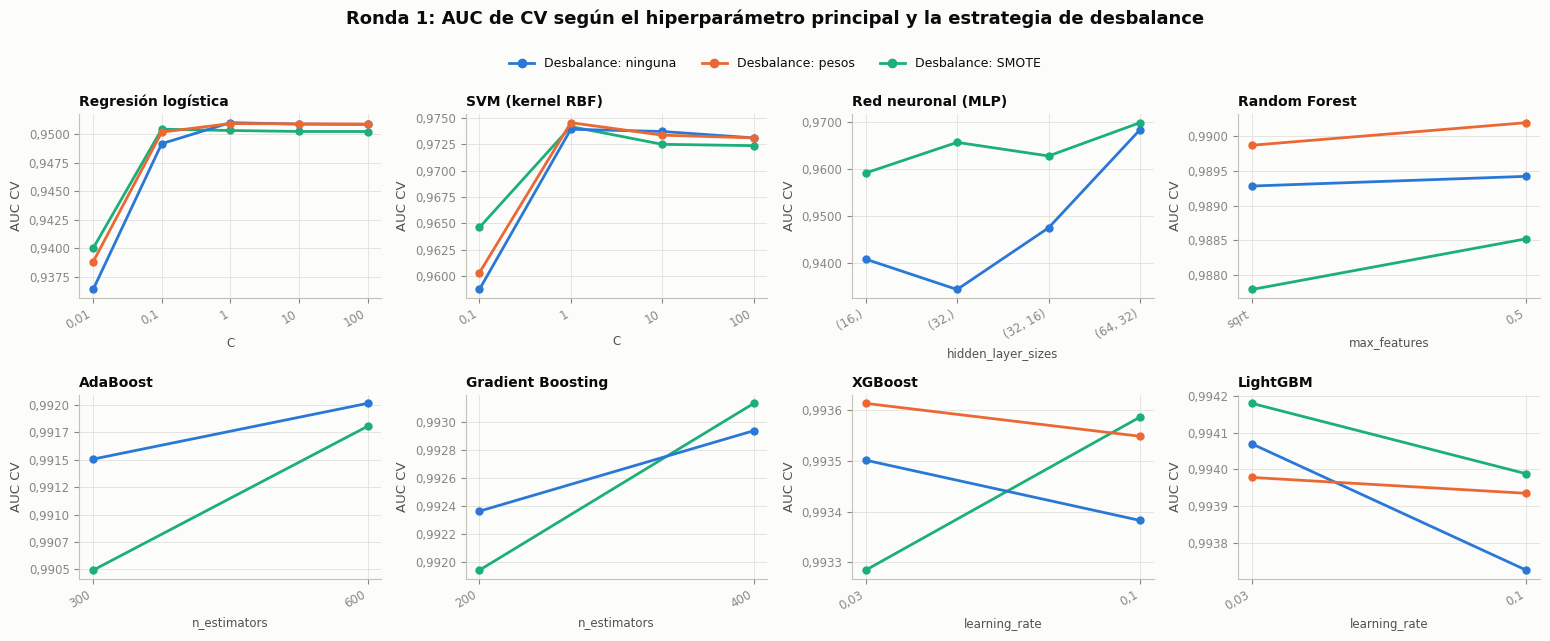

Hiperparámetros con el óptimo en un extremo de la grilla (ronda 1):


,modelo,hiperparametro,elegido,probados,extremo
0,Red neuronal (MLP),hidden_layer_sizes,"(64, 32)","[(16,), (32,), (32, 16), (64, 32)]",máximo
1,Random Forest,min_samples_leaf,1,"[1, 5]",mínimo
2,AdaBoost,estimator__max_depth,2,"[1, 2]",máximo
3,AdaBoost,n_estimators,600,"[300, 600]",máximo
4,AdaBoost,learning_rate,1.0,"[0.1, 0.5, 1.0]",máximo
5,Gradient Boosting,n_estimators,400,"[200, 400]",máximo
6,Gradient Boosting,learning_rate,0.1,"[0.05, 0.1]",máximo
7,Gradient Boosting,max_depth,3,"[2, 3]",máximo
8,XGBoost,n_estimators,600,"[300, 600]",máximo
9,XGBoost,learning_rate,0.03,"[0.03, 0.1]",mínimo


In [21]:
parametro_principal = {
    "Regresión logística": "C", "SVM (kernel RBF)": "C", "Red neuronal (MLP)": "hidden_layer_sizes",
    "Random Forest": "max_features", "AdaBoost": "n_estimators", "Gradient Boosting": "n_estimators",
    "XGBoost": "learning_rate", "LightGBM": "learning_rate",
}
paneles = {nombre: (ronda_1.modelos[nombre].resultados(), parametro) for nombre, parametro in parametro_principal.items()}
fig = graficos_modelado.efecto_hiperparametros(
    paneles, "Ronda 1: AUC de CV según el hiperparámetro principal y la estrategia de desbalance")
reportes.mostrar_figura(fig, "modelado_01_efecto_hiperparametros")

print("Hiperparámetros con el óptimo en un extremo de la grilla (ronda 1):")
bordes_ronda_1 = ronda_1.hiperparametros_en_borde()
reportes.guardar_tabla(bordes_ronda_1, "modelado_bordes_ronda_1", decimales=None, indice=False)
display(bordes_ronda_1)

#### Lectura y decisión

- **Ojo con la escala:** cada panel tiene su propio eje, muy estrecho en boosting.
- **La estrategia solo importa lejos del óptimo:** en la red con (32,), SMOTE logra 0,9657 y sin balanceo 0,9344; con (64, 32), 0,9699 frente a 0,9684.
- **14 hiperparámetros en un extremo**, sobre todo en boosting y en la arquitectura de la red. SVM y Random Forest se revisaron a mano porque sus grillas mezclan textos y números.

**Decisión.** Se amplían las grillas de siete modelos (ronda 2); la logística no, porque su C = 1 quedó en el interior.

### 4.4 Rondas 2 y 3: ampliación de las grillas

Cada grilla ampliada contiene el óptimo anterior y lo extiende hacia el borde (`GRILLAS_RONDA_2` y `GRILLAS_RONDA_3`), solo con la estrategia "ninguna". **Regla:** otra ronda solo si el modelo mantiene un borde **y** su ronda nueva mejoró el AUC por más de una desviación; si no, el borde se declara.

In [22]:
ronda_2 = comparacion.entrenar_o_cargar(comparacion.ampliar_grillas(ronda_1, comparacion.GRILLAS_RONDA_2),
                                        particion.X_train, particion.y_train,
                                        config.RUTA_EXPERIMENTOS, "ronda_2", reentrenar=REENTRENAR)
rondas_1_2 = comparacion.comparar_rondas(ronda_1, ronda_2)
reportes.guardar_tabla(rondas_1_2, "modelado_rondas_1_2")
display(rondas_1_2.round(4))
a_ampliar = comparacion.modelos_a_ampliar(ronda_1, ronda_2)
print(f"Modelos que cumplen la regla para una ronda 3: {a_ampliar}")
assert set(a_ampliar) == set(comparacion.GRILLAS_RONDA_3), "La ronda 3 definida no coincide con la regla"

ronda_3 = comparacion.entrenar_o_cargar(comparacion.ampliar_grillas(ronda_2, comparacion.GRILLAS_RONDA_3),
                                        particion.X_train, particion.y_train,
                                        config.RUTA_EXPERIMENTOS, "ronda_3", reentrenar=REENTRENAR)
rondas_2_3 = comparacion.comparar_rondas(ronda_2, ronda_3)
reportes.guardar_tabla(rondas_2_3, "modelado_rondas_2_3")
display(rondas_2_3.round(4))
print(f"Modelos que cumplen la regla para una ronda 4: {comparacion.modelos_a_ampliar(ronda_2, ronda_3)}")

comparador = comparacion.combinar(ronda_1, ronda_2, ronda_3)
print("Bordes que se declaran en la versión final de cada modelo:")
bordes_finales = comparador.hiperparametros_en_borde()
reportes.guardar_tabla(bordes_finales, "modelado_bordes_final", decimales=None, indice=False)
display(bordes_finales)

   1/7 SVM (kernel RBF): 12 candidatos x 5 pliegues... AUC CV 0.9753 (54 s)
   2/7 Red neuronal (MLP): 9 candidatos x 5 pliegues... AUC CV 0.9725 (37 s)
   3/7 Random Forest: 18 candidatos x 5 pliegues... AUC CV 0.9899 (113 s)
   4/7 AdaBoost: 12 candidatos x 5 pliegues... AUC CV 0.9927 (250 s)
   5/7 Gradient Boosting: 8 candidatos x 5 pliegues... AUC CV 0.9935 (113 s)
   6/7 XGBoost: 18 candidatos x 5 pliegues... AUC CV 0.9936 (45 s)
   7/7 LightGBM: 18 candidatos x 5 pliegues... AUC CV 0.9941 (100 s)


,auc_cv_anterior,auc_cv_nueva,cambio,desv_nueva,hiperparametros_anterior,hiperparametros_nueva
modelo,,,,,,
SVM (kernel RBF),0.9739,0.9753,0.0013,0.0026,"{'C': 1, 'gamma': 0.1}","{'C': 3, 'gamma': 0.1}"
Red neuronal (MLP),0.9684,0.9725,0.0042,0.0025,"{'alpha': 0.001, 'hidden_layer_sizes': (64, 32)}","{'alpha': 0.003, 'hidden_layer_sizes': (128, 64)}"
Random Forest,0.9894,0.9899,0.0005,0.0024,"{'max_depth': 12, 'max_features': 0.5, 'min_samples_leaf': 1}","{'max_depth': None, 'max_features': 0.3, 'min_samples_leaf': 1}"
AdaBoost,0.9920,0.9927,0.0007,0.0015,"{'estimator__max_depth': 2, 'learning_rate': 1.0, 'n_estimators': 600}","{'estimator__max_depth': 3, 'learning_rate': 0.5, 'n_estimators': 1000}"
Gradient Boosting,0.9929,0.9935,0.0005,0.0020,"{'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 400}","{'learning_rate': 0.1, 'max_depth': 4, 'n_estimators': 400}"
XGBoost,0.9935,0.9936,0.0001,0.0017,"{'learning_rate': 0.03, 'max_depth': 5, 'n_estimators': 600}","{'learning_rate': 0.05, 'max_depth': 5, 'n_estimators': 600}"
LightGBM,0.9941,0.9941,0.0001,0.0011,"{'learning_rate': 0.03, 'n_estimators': 600, 'num_leaves': 31}","{'learning_rate': 0.03, 'n_estimators': 1000, 'num_leaves': 31}"


Modelos que cumplen la regla para una ronda 3: ['Red neuronal (MLP)']
   1/1 Red neuronal (MLP): 6 candidatos x 5 pliegues... AUC CV 0.9729 (71 s)


,auc_cv_anterior,auc_cv_nueva,cambio,desv_nueva,hiperparametros_anterior,hiperparametros_nueva
modelo,,,,,,
Red neuronal (MLP),0.9725,0.9729,0.0004,0.0038,"{'alpha': 0.003, 'hidden_layer_sizes': (128, 64)}","{'alpha': 0.01, 'hidden_layer_sizes': (256, 128)}"


Modelos que cumplen la regla para una ronda 4: []
Bordes que se declaran en la versión final de cada modelo:


,modelo,hiperparametro,elegido,probados,extremo
0,Red neuronal (MLP),hidden_layer_sizes,"(256, 128)","[(128, 64), (256, 128)]",máximo
1,Random Forest,min_samples_leaf,1,"[1, 2]",mínimo
2,Random Forest,max_features,0.3,"[0.3, 0.5, 0.7]",mínimo
3,AdaBoost,estimator__max_depth,3,"[2, 3]",máximo
4,AdaBoost,n_estimators,1000,"[600, 1000]",máximo
5,AdaBoost,learning_rate,0.5,"[0.5, 1.0, 1.5]",mínimo
6,Gradient Boosting,n_estimators,400,"[400, 800]",mínimo
7,Gradient Boosting,learning_rate,0.1,"[0.1, 0.2]",mínimo
8,Gradient Boosting,max_depth,4,"[3, 4]",máximo
9,XGBoost,n_estimators,600,"[600, 1000, 1500]",mínimo


#### Lectura y decisión

- **Ronda 2:** cambios de 0,0001 (XGBoost) a 0,0013 (SVM), todos bajo la desviación; la excepción es la red neuronal (+0,0042 frente a 0,0025).
- **Ronda 3, solo la red:** +0,0004 (desviación 0,0038). Ningún modelo cumple la regla para una ronda 4.
- **13 bordes declarados**, casi todos en boosting, en una meseta.

**Decisión.** Se detiene la búsqueda: seguir costaría cómputo sin cambiar el ranking. Es el criterio de parada.

### 4.5 Comparación final y finalistas

Se comparan AUC medio, brecha y tiempo de la mejor versión de cada modelo. La **comparación pareada** contra el mejor (pliegue a pliegue) separa diferencias reales de ruido. Son **finalistas** los modelos a menos de una desviación (entre pliegues) del mejor: un criterio holgado de empate.

,familia,auc_cv,auc_cv_desv,ap_cv,auc_train,brecha_train_cv,tiempo_ajuste_s,candidatos,estrategia,mejores_hiperparametros
modelo,,,,,,,,,,
LightGBM,boosting,0.9941,0.0011,0.9733,1.0000,0.0059,4.8300,18,ninguna,"{'learning_rate': 0.03, 'n_estimators': 1000, 'num_leaves': 31}"
XGBoost,boosting,0.9936,0.0017,0.9712,1.0000,0.0064,3.2478,18,ninguna,"{'learning_rate': 0.05, 'max_depth': 5, 'n_estimators': 600}"
Gradient Boosting,boosting,0.9935,0.0020,0.9714,1.0000,0.0065,22.5843,8,ninguna,"{'learning_rate': 0.1, 'max_depth': 4, 'n_estimators': 400}"
AdaBoost,boosting,0.9927,0.0015,0.9676,1.0000,0.0073,65.4560,12,ninguna,"{'estimator__max_depth': 3, 'learning_rate': 0.5, 'n_estimators': 1000}"
Random Forest,bagging,0.9899,0.0024,0.9552,1.0000,0.0101,12.3542,18,ninguna,"{'max_depth': None, 'max_features': 0.3, 'min_samples_leaf': 1}"
SVM (kernel RBF),kernel,0.9753,0.0026,0.9043,0.9997,0.0245,4.4637,12,ninguna,"{'C': 3, 'gamma': 0.1}"
Red neuronal (MLP),red neuronal,0.9729,0.0038,0.9024,0.9957,0.0228,36.7345,6,ninguna,"{'alpha': 0.01, 'hidden_layer_sizes': (256, 128)}"
Regresión logística,lineal,0.9510,0.0018,0.8365,0.9538,0.0027,1.9147,30,ninguna,"{'C': 1, 'penalty': 'l1'}"


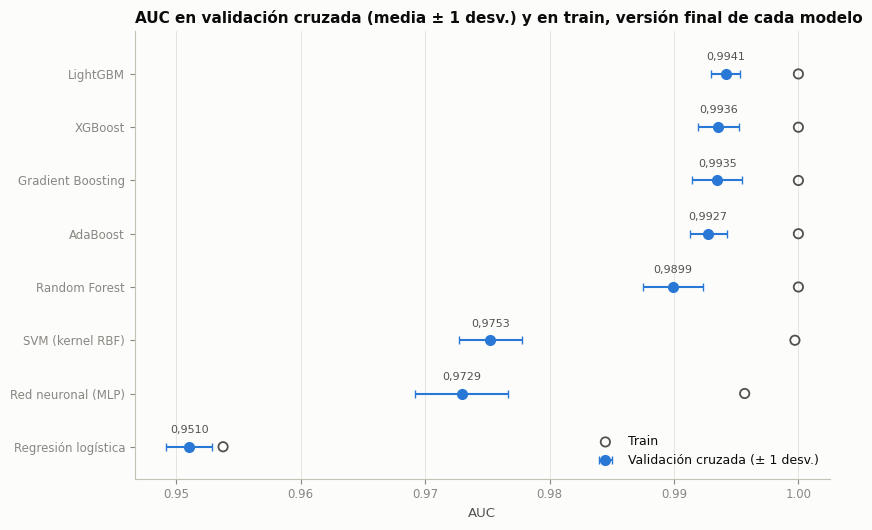

,diferencia_media,diferencia_desv,pliegues_por_debajo_del_mejor
modelo,,,
LightGBM,0.0000,0.0000,0
XGBoost,-0.0006,0.0006,4
Gradient Boosting,-0.0007,0.0011,4
AdaBoost,-0.0014,0.0003,5
Random Forest,-0.0042,0.0016,5
SVM (kernel RBF),-0.0189,0.0020,5
Red neuronal (MLP),-0.0212,0.0037,5
Regresión logística,-0.0431,0.0021,5


Finalistas (a menos de 1 desviación del mejor): ['LightGBM', 'XGBoost', 'Gradient Boosting']


In [23]:
tabla_final_cv = comparador.tabla_cv()
reportes.guardar_tabla(tabla_final_cv[columnas_tabla], "modelado_tabla_cv")
display(tabla_final_cv[columnas_tabla].round(4))

fig = graficos_modelado.auc_cv_por_modelo(
    tabla_final_cv, "AUC en validación cruzada (media ± 1 desv.) y en train, versión final de cada modelo")
reportes.mostrar_figura(fig, "modelado_02_auc_cv_final")

pareada = comparador.comparacion_pareada()
reportes.guardar_tabla(pareada, "modelado_pareada")
display(pareada.round(4))
finalistas = comparador.finalistas()
print(f"Finalistas (a menos de 1 desviación del mejor): {finalistas}")

#### Lectura y decisión

- **LightGBM:** AUC de CV 0,9941 ± 0,0011, el más alto y con menor variación.
- **Pareada:** XGBoost y Gradient Boosting quedan 0,0006 y 0,0007 por debajo (en 4 de 5 pliegues cada uno): una diferencia sin relevancia práctica. Los demás quedan por debajo en los 5 pliegues.
- **Costo:** 4,83 s por ajuste en LightGBM, 3,25 s en XGBoost y 22,58 s en Gradient Boosting (ejecución del equipo). Los tiempos cambian con la carga del computador y no se usan para decidir. Train llega a 1,0000 en los tres, con brechas de 0,0059 a 0,0065, habitual en boosting.

**Decisión.** Pasan a test los tres finalistas y la logística como referencia interpretable. Preferencia preliminar: **LightGBM** (mayor AUC y menor variación); se confirma en 5.2.

### 4.6 PyCaret como referencia AutoML

PyCaret entrena unos quince algoritmos con valores por defecto sobre train. Sirve de contraste (si uno que no probamos quedara muy por encima, habría que revisarlo), no para elegir.

In [24]:
tabla_pycaret = comparacion.referencia_pycaret(particion.X_train, particion.y_train)
reportes.guardar_tabla(tabla_pycaret, "modelado_pycaret", decimales=None)
display(tabla_pycaret)

,Model,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC,TT (Sec)
lightgbm,Light Gradient Boosting Machine,0.9702,0.9931,0.8722,0.9384,0.9040,0.8864,0.8873,0.406
xgboost,Extreme Gradient Boosting,0.9691,0.9922,0.8684,0.9351,0.9004,0.8822,0.8831,0.272
gbc,Gradient Boosting Classifier,0.9630,0.9892,0.8271,0.9356,0.8776,0.8559,0.8584,0.792
rf,Random Forest Classifier,0.9475,0.9847,0.7377,0.9199,0.8182,0.7880,0.7950,0.372
ada,Ada Boost Classifier,0.9554,0.9829,0.8377,0.8797,0.8578,0.8314,0.8320,0.372
et,Extra Trees Classifier,0.9242,0.9712,0.5764,0.9222,0.7084,0.6677,0.6926,0.324
lr,Logistic Regression,0.9133,0.9375,0.6369,0.7832,0.7015,0.6515,0.6569,1.092
ridge,Ridge Classifier,0.9100,0.9351,0.5274,0.8578,0.6519,0.6038,0.6280,0.172
lda,Linear Discriminant Analysis,0.9145,0.9351,0.6542,0.7793,0.7101,0.6605,0.6647,0.184
svm,SVM - Linear Kernel,0.9005,0.9190,0.5946,0.7358,0.6551,0.5980,0.6041,0.192


#### Lectura y decisión

- **Coinciden los tres primeros:** LightGBM (0,9931), XGBoost (0,9922) y Gradient Boosting (0,9892); Random Forest y AdaBoost cambian de orden frente a nuestra CV. Los valores no son comparables uno a uno: PyCaret valida sobre el 80 % de train, con otros pliegues y con valores por defecto.
- **Nada fuera de nuestro catálogo compite:** el mejor es Extra Trees (0,9712). El `dummy` da AUC 0,5000 y accuracy 0,8394, el baseline de 2.1.

**Decisión.** PyCaret confirma que boosting gana; no se agrega ningún modelo.

### 4.7 Conclusión de la Fase 4

1. **Boosting gana:** LightGBM, XGBoost y Gradient Boosting empatan (AUC de CV de 0,9935 a 0,9941), PyCaret lo confirma y SMOTE y pesos no mejoran el orden de los clientes.
2. **La búsqueda se detuvo con un criterio** y los bordes restantes quedan declarados.
3. **El test sigue sin tocarse.**

## CRISP-DM Fase 5: Evaluación

### 5.1 Desempeño en test

Los tres finalistas y la logística de referencia, reajustados con todo train, predicen **una sola vez** a los 2.026 clientes de test.

**Regla fijada antes de ver el test:** se elige **LightGBM**, salvo que otro finalista lo supere con un IC de 95 % (bootstrap) que excluya el 0; entre los que no se distingan, el más simple o rápido.

**Umbral** (probabilidad desde la que se dice "se va"): se reportan **0,5 para todos** y el **umbral de máximo F1** de cada modelo, calculado con sus predicciones fuera de pliegue en train, sin mirar el test. El umbral de operación depende de la capacidad de contacto (5.4).

#### Modelos evaluados y umbral de máximo F1 fijado con train

In [25]:
evaluados = finalistas + ["Regresión logística"]
pipelines_finales = {nombre: comparador.modelos[nombre].busqueda_.best_estimator_ for nombre in evaluados}
for nombre in evaluados:
    print(f"{nombre}: {comparador.modelos[nombre].resumen()['mejores_hiperparametros']}")

cv = modelos.validacion_cruzada()
oof = evaluacion.oof_de_modelos(pipelines_finales, particion.X_train, particion.y_train, cv)
auc_cv_medio = {nombre: comparador.modelos[nombre].resumen()["auc_cv"] for nombre in evaluados}
umbrales_f1, resumen_oof = evaluacion.resumen_oof(oof, particion.y_train, auc_cv_medio)
reportes.guardar_tabla(resumen_oof, "test_umbrales_oof")
display(resumen_oof.round(4))

LightGBM: {'learning_rate': 0.03, 'n_estimators': 1000, 'num_leaves': 31}
XGBoost: {'learning_rate': 0.05, 'max_depth': 5, 'n_estimators': 600}
Gradient Boosting: {'learning_rate': 0.1, 'max_depth': 4, 'n_estimators': 400}
Regresión logística: {'C': 1, 'penalty': 'l1'}


,auc_oof,auc_cv_medio,umbral_max_f1
LightGBM,0.9941,0.9941,0.2219
XGBoost,0.9936,0.9936,0.4041
Gradient Boosting,0.9934,0.9935,0.4263
Regresión logística,0.9509,0.9510,0.4239


#### Lectura y decisión

- **Coherencia:** el AUC fuera de pliegue difiere del AUC medio de CV en menos de 0,0002: los pipelines evaluados son los elegidos en la Fase 4.
- **El umbral de máximo F1 es menor que 0,5 y distinto en cada modelo** (0,2219 en LightGBM, 0,4041 en XGBoost, 0,4263 en Gradient Boosting, 0,4239 en la logística): por eso se reportan las dos vistas.

#### Predicción única en test y métricas de los finalistas

In [26]:
probabilidades_test = {nombre: pipe.predict_proba(particion.X_test)[:, 1] for nombre, pipe in pipelines_finales.items()}
y_test = particion.y_test
print(f"Clientes de test: {len(y_test):,} | churners: {int(y_test.sum())} ({y_test.mean():.2%})")
print(f"Baseline trivial en test (decir que nadie se va): accuracy {1 - y_test.mean():.2%}")

metricas_05, metricas_f1 = evaluacion.metricas_en_test(y_test, probabilidades_test, umbrales_f1)
reportes.guardar_tabla(metricas_05, "test_metricas_umbral_05", decimales=None)
reportes.guardar_tabla(metricas_f1, "test_metricas_umbral_f1", decimales=None)
columnas_metricas = ["auc", "ap", "log_loss", "brier", "umbral", "accuracy", "sensibilidad",
                     "precision", "f1", "tp", "fp"]  # la tabla completa queda en reports/tables
print("Umbral 0,5 para todos:")
display(metricas_05[columnas_metricas].astype(float).round(4))
print("Umbral de máximo F1 (fijado con train):")
display(metricas_f1[columnas_metricas].astype(float).round(4))

cv_vs_test = evaluacion.comparar_cv_test(resumen_oof, metricas_05)
reportes.guardar_tabla(cv_vs_test, "test_cv_vs_test")
display(cv_vs_test.round(4))

Clientes de test: 2,026 | churners: 325 (16.04%)
Baseline trivial en test (decir que nadie se va): accuracy 83.96%
Umbral 0,5 para todos:


,auc,ap,log_loss,brier,umbral,accuracy,sensibilidad,precision,f1,tp,fp
LightGBM,0.9933,0.9686,0.1019,0.0233,0.5,0.9733,0.8769,0.9532,0.9135,285.0,14.0
XGBoost,0.9934,0.9679,0.0803,0.0226,0.5,0.9719,0.8615,0.9589,0.9076,280.0,12.0
Gradient Boosting,0.9927,0.9670,0.0848,0.0228,0.5,0.9738,0.8738,0.9595,0.9147,284.0,12.0
Regresión logística,0.9445,0.8039,0.2072,0.0617,0.5,0.9210,0.6523,0.8185,0.7260,212.0,47.0


Umbral de máximo F1 (fijado con train):


,auc,ap,log_loss,brier,umbral,accuracy,sensibilidad,precision,f1,tp,fp
LightGBM,0.9933,0.9686,0.1019,0.0233,0.2219,0.9709,0.8985,0.9182,0.9082,292.0,26.0
XGBoost,0.9934,0.9679,0.0803,0.0226,0.4041,0.9714,0.8769,0.9406,0.9076,285.0,18.0
Gradient Boosting,0.9927,0.9670,0.0848,0.0228,0.4263,0.9733,0.8738,0.9562,0.9132,284.0,13.0
Regresión logística,0.9445,0.8039,0.2072,0.0617,0.4239,0.9210,0.7046,0.7816,0.7411,229.0,64.0


,auc_cv,auc_test,diferencia_test_menos_cv
LightGBM,0.9941,0.9933,-0.0008
XGBoost,0.9936,0.9934,-0.0002
Gradient Boosting,0.9935,0.9927,-0.0008
Regresión logística,0.9510,0.9445,-0.0065


#### Curvas ROC y PR, y matrices de confusión

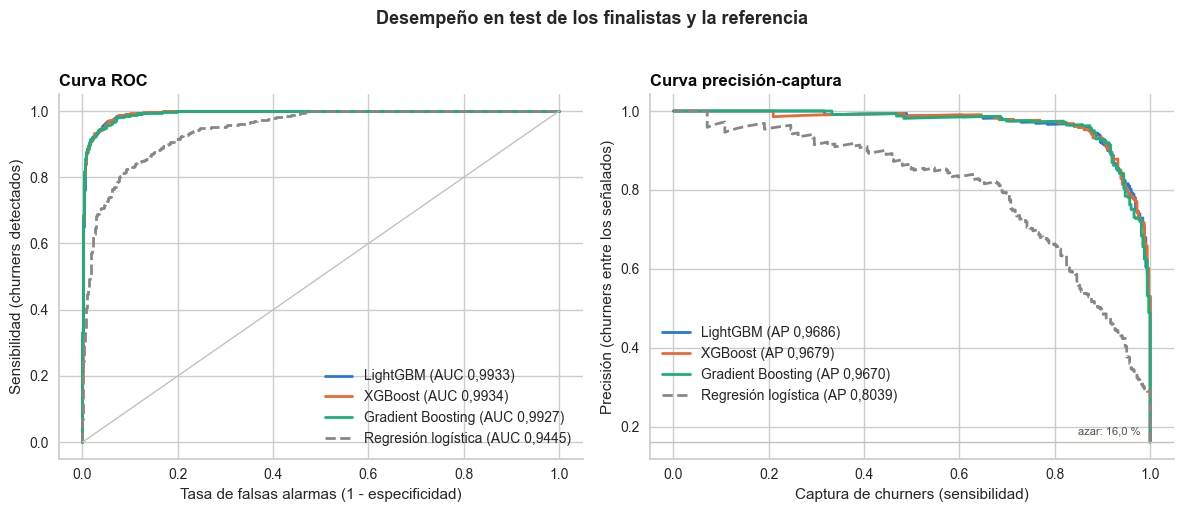

Lectura de las curvas en puntos concretos (test):


,precision_con_captura_80,precision_con_captura_90,precision_con_captura_95,sensibilidad_con_falsas_alarmas_5
LightGBM,0.9677,0.9185,0.8158,0.9662
XGBoost,0.9740,0.9302,0.8047,0.9600
Gradient Boosting,0.9744,0.9274,0.7848,0.9538
Regresión logística,0.6633,0.4908,0.4034,0.7262


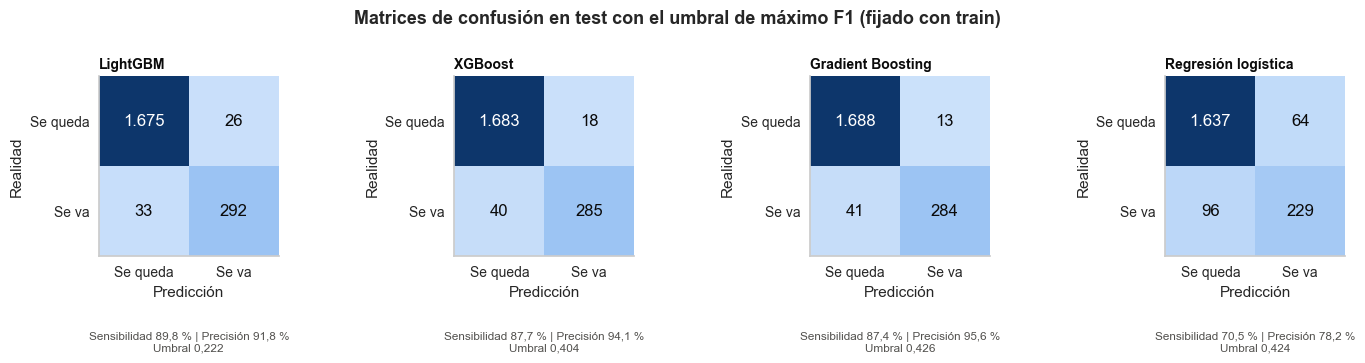

WindowsPath('C:/Users/PERSONAL/Projects/U-Analitica II/Proyecto Final Analitica II/Trabajo Juanfer & Juandi/reports/figures/test_02_matrices_confusion.png')

In [27]:
fig = graficos_modelado.curvas_roc_pr(y_test, probabilidades_test, "Desempeño en test de los finalistas y la referencia",
                                      referencia_gris="Regresión logística")
reportes.mostrar_figura(fig, "test_01_roc_pr")

puntos_operacion = pd.DataFrame({n: evaluacion.puntos_de_operacion(y_test, p) for n, p in probabilidades_test.items()}).T
reportes.guardar_tabla(puntos_operacion, "test_puntos_operacion")
print("Lectura de las curvas en puntos concretos (test):")
display(puntos_operacion.round(4))

resultados_f1 = {n: evaluacion.calcular_metricas(y_test, p, umbrales_f1[n]) for n, p in probabilidades_test.items()}
fig = graficos_modelado.matrices_confusion(
    resultados_f1, "Matrices de confusión en test con el umbral de máximo F1 (fijado con train)")
reportes.mostrar_figura(fig, "test_02_matrices_confusion")

#### Lectura y decisión

- **El test confirma la CV:** AUC de 0,9933 en LightGBM y 0,9445 en la logística; los finalistas caen de 0,0002 a 0,0008 frente a la CV y la logística 0,0065. No hay sobreajuste a los pliegues.
- **LightGBM detecta 285 de los 325 churners** con el umbral 0,5 (sensibilidad 87,69 %; precisión 95,32 %, 14 falsas alarmas) y 292 con el de máximo F1, 0,2219 (89,85 %; 91,82 %, 26 falsas alarmas). La logística detecta 229 (70,46 %) con 64 falsas alarmas.
- **Curvas:** los tres finalistas casi se superponen. Tolerando 5 % de falsas alarmas, LightGBM detecta 96,62 % de los churners y la logística 72,62 %.
- **Por qué el AUC es tan alto:** el objetivo sale solo de `attrition_flag`, que se elimina antes de modelar; `clientnum` es índice y no variable; y la validación exige exactamente las 21 columnas de la Tabla 1 del caso. Ninguna variable sola delata el resultado (AUC univariado máximo de 0,796, 2.2): la cifra sale de combinar las variables de actividad (5.6). Lo que estos datos no permiten descartar es que esa actividad se haya medido cerca del retiro (5.8).
- **Alerta:** LightGBM tiene el log loss más alto (0,1019 frente a 0,0803 y 0,0848): algo **sobreconfiado** en los extremos; se revisa en 5.3.

### 5.2 ¿Las diferencias son reales? Bootstrap pareado

Se remuestrean los 2.026 clientes de test 2.000 veces (manteniendo el 16 % de churners) y se recalcula el AUC de los cuatro modelos sobre los mismos clientes: da un IC de 95 % para cada AUC y para su diferencia contra LightGBM.

In [28]:
tabla_bootstrap = evaluacion.bootstrap_auc(y_test, probabilidades_test, referencia="LightGBM",
                                           n_remuestras=2000, semilla=config.SEMILLA)
reportes.guardar_tabla(tabla_bootstrap, "test_bootstrap_auc")
display(tabla_bootstrap.round(4))

# Lo que mide el banco: churners capturados con cada capacidad, en train (fuera de pliegue) y en test
captura_modelos = pd.concat({"train fuera de pliegue": negocio.escenarios_por_modelo(particion.y_train, oof),
                             "test": negocio.escenarios_por_modelo(y_test, probabilidades_test)}, axis=1)
reportes.guardar_tabla(captura_modelos, "test_captura_por_modelo")
print(f"Churners capturados con el 20 % de contacto (de {int(particion.y_train.sum()):,} en train y {int(y_test.sum())} en test):")
display(captura_modelos.xs("churners_20", axis=1, level=1))

,auc_test,auc_ic95_inf,auc_ic95_sup,dif_vs_referencia,dif_ic95_inf,dif_ic95_sup,prop_remuestras_mejor_que_ref,equivalente_a_referencia
modelo,,,,,,,,
LightGBM,0.9933,0.9906,0.9957,0.0000,0.0000,0.0000,0.000,True
XGBoost,0.9934,0.9906,0.9957,0.0000,-0.0007,0.0008,0.547,True
Gradient Boosting,0.9927,0.9897,0.9953,-0.0006,-0.0017,0.0005,0.149,True
Regresión logística,0.9445,0.9323,0.9550,-0.0488,-0.0602,-0.0389,0.000,False


Churners capturados con el 20 % de contacto (de 1,302 en train y 325 en test):


,train fuera de pliegue,test
LightGBM,1269.0,315.0
XGBoost,1271.0,314.0
Gradient Boosting,1270.0,311.0
Regresión logística,1076.0,263.0


#### Lectura y decisión

- **Gradient Boosting** (-0,0006; IC de -0,0017 a 0,0005) y **XGBoost** (+0,00004; IC de -0,0007 a 0,0008) **no se distinguen** de LightGBM (AUC 0,9933; IC de 0,9906 a 0,9957), y cualquier diferencia compatible con los datos es irrelevante en la práctica. La logística queda 0,0488 por debajo (IC de -0,0602 a -0,0389).
- **En la métrica del banco tampoco hay diferencia:** con el 20 % de contacto, LightGBM captura 1.269 de 1.302 churners en train y 315 de 325 en test; los otros dos finalistas quedan a no más de 4 clientes, y la logística en 1.076 y 263.

**Decisión, según la regla previa.** **El modelo final es LightGBM.** Ningún finalista lo supera con un IC que excluya el 0, así que se mantiene; además tiene la menor variación entre pliegues. No lo desempata una ventaja en churners capturados ni la velocidad: entre LightGBM y XGBoost el orden de los tiempos cambia de una ejecución a otra (4.5).

### 5.3 Calibración: ¿la probabilidad significa lo que dice?

Las decisiones de 5.4 y 5.5 usan el **orden** de los clientes, no el valor de la probabilidad. La calibración importa si el banco quisiera leer la probabilidad como un porcentaje literal (por ejemplo, para calcular pérdida esperada). Se revisa por deciles y por rangos fijos de probabilidad; el **Brier** (error cuadrático de la probabilidad) lo resume en un número.

,error_calibracion,error_calibracion_oof_train,brier,prob_media_predicha,tasa_real
LightGBM,0.0148,0.0095,0.0233,0.1484,0.1604
XGBoost,0.0125,0.0082,0.0226,0.1486,0.1604
Gradient Boosting,0.0152,0.0097,0.0228,0.1475,0.1604
Regresión logística,0.0099,0.0046,0.0617,0.1529,0.1604


LightGBM en test por rangos de probabilidad (probabilidad promedio frente a tasa real):


,clientes,prob_media,tasa_real,diferencia
rango,,,,
0% a 5%,1672,0.0011,0.0138,-0.0127
5% a 20%,33,0.1011,0.2424,-0.1413
20% a 40%,15,0.2798,0.3333,-0.0535
40% a 60%,13,0.4964,0.6154,-0.1190
60% a 80%,15,0.7193,0.8000,-0.0807
80% a 95%,24,0.8826,0.9167,-0.0341
95% a 100%,254,0.9960,0.9724,0.0236


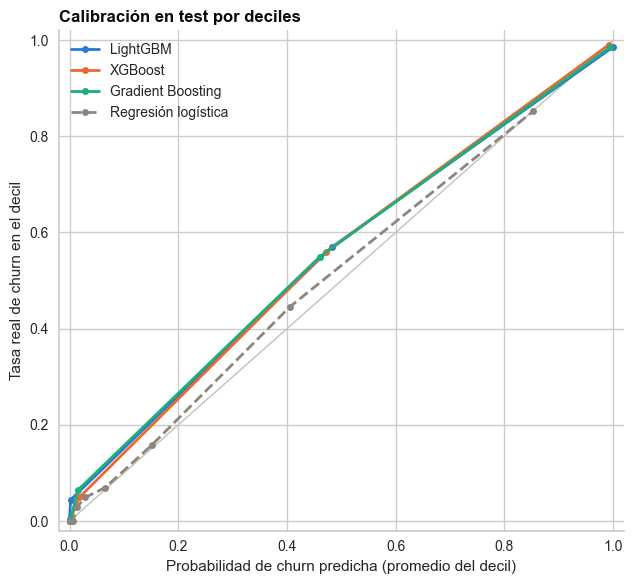

WindowsPath('C:/Users/PERSONAL/Projects/U-Analitica II/Proyecto Final Analitica II/Trabajo Juanfer & Juandi/reports/figures/test_03_calibracion.png')

In [29]:
tablas_calibracion = {n: evaluacion.tabla_calibracion(y_test, p) for n, p in probabilidades_test.items()}
resumen_calibracion = pd.DataFrame({
    "error_calibracion": {n: evaluacion.error_calibracion(t) for n, t in tablas_calibracion.items()},
    "error_calibracion_oof_train": {n: evaluacion.error_calibracion(evaluacion.tabla_calibracion(particion.y_train, p))
                                    for n, p in oof.items()},
    "brier": metricas_05["brier"].astype(float),
    "prob_media_predicha": {n: float(np.mean(p)) for n, p in probabilidades_test.items()},
    "tasa_real": float(y_test.mean()),
})
reportes.guardar_tabla(resumen_calibracion, "test_calibracion")
display(resumen_calibracion.round(4))
reportes.guardar_tabla(tablas_calibracion["LightGBM"], "test_calibracion_deciles_lightgbm")
calibracion_rangos = evaluacion.tabla_calibracion_rangos(y_test, probabilidades_test["LightGBM"])
reportes.guardar_tabla(calibracion_rangos, "test_calibracion_rangos_lightgbm")
print("LightGBM en test por rangos de probabilidad (probabilidad promedio frente a tasa real):")
display(calibracion_rangos.round(4))

fig = graficos_modelado.diagrama_calibracion(tablas_calibracion, "Calibración en test por deciles",
                                             referencia_gris="Regresión logística")
reportes.mostrar_figura(fig, "test_03_calibracion")

#### Lectura y decisión

- **Por deciles el error es pequeño** (0,0148 en LightGBM), pero la medida se diluye: la mayoría de deciles de LightGBM tiene probabilidad y churn de 0. Bien calibrado no es lo mismo que útil: el Brier de la logística (0,0617) casi triplica el de LightGBM (0,0233).
- **Por rangos, LightGBM subestima el riesgo intermedio:** de 5 % a 20 % predice 10,11 % y se van 24,24 % (33 clientes); sobre 95 % predice 99,60 % y se van 97,24 % (254). Son pocos clientes por rango: el patrón es indicativo.

**Decisión.** No se recalibra, porque no cambiaría el orden de los clientes. Recalibrar dentro de train (`CalibratedClassifierCV`) queda como mejora (6.4) si el banco quiere leer la probabilidad como un porcentaje literal.

### 5.4 Escenarios de contacto

Un AUC de 0,99 no dice cuántos clientes contactar. Se ordena a todos por probabilidad y se contacta al top k %; la probabilidad del último contactado es el **umbral implícito**. Las cifras para decidir salen de las predicciones **fuera de pliegue en train** (8.101 clientes) y el test (2.026) solo confirma.

#### Escenarios con train fuera de pliegue, para decidir

In [30]:
modelo_final = "LightGBM"
escenarios_oof = negocio.tabla_escenarios(particion.y_train, oof[modelo_final])
incremental_oof = negocio.tabla_incremental(escenarios_oof)
reportes.guardar_tabla(escenarios_oof, "negocio_escenarios_oof")
reportes.guardar_tabla(incremental_oof, "negocio_incremental_oof")
display(escenarios_oof.round(4))
display(incremental_oof.round(4))

escenarios_oof_logistica = negocio.tabla_escenarios(particion.y_train, oof["Regresión logística"])
reportes.guardar_tabla(escenarios_oof_logistica, "negocio_escenarios_oof_logistica")  # referencia (tabla de 5.2)

,contactados,churners_capturados,captura,precision,lift,beneficios_a_no_churners,churners_sin_contactar,umbral_implicito,captura_maxima_posible
capacidad,,,,,,,,,
0.1,810,799,0.6137,0.9864,6.1375,11,503,0.9982,0.6221
0.2,1620,1269,0.9747,0.7833,4.8739,351,33,0.0060,1.0000
0.3,2430,1296,0.9954,0.5333,3.3184,1134,6,0.0001,1.0000


,contactos_adicionales,churners_adicionales,precision_marginal
capacidad,,,
0.1,810,799,0.9864
0.2,810,470,0.5802
0.3,810,27,0.0333


WindowsPath('C:/Users/PERSONAL/Projects/U-Analitica II/Proyecto Final Analitica II/Trabajo Juanfer & Juandi/reports/tables/negocio_escenarios_oof_logistica.csv')

#### Lectura y decisión (train, fuera de pliegue)

- **Con el 10 % casi no hay desperdicio** (precisión de 98,64 %) pero solo se cubre el 61,37 % de los churners; **el 20 % cubre casi todo** (97,47 %, 1.269 de 1.302 con 1.620 contactos). Pasar a 30 % agrega 810 contactos que encuentran solo 27 churners (precisión marginal de 3,33 %, frente a 58,02 % del paso de 10 % a 20 %).
- **Elegir bien el modelo vale dinero:** con el mismo 20 %, LightGBM captura 193 churners más que la logística (5.2).

#### Confirmación en test con intervalos de confianza

,contactados,churners_capturados,captura,precision,lift,beneficios_a_no_churners,churners_sin_contactar,umbral_implicito,captura_maxima_posible,captura_ic95_inf,captura_ic95_sup,precision_ic95_inf,precision_ic95_sup
capacidad,,,,,,,,,,,,,
0.1,203,200,0.6154,0.9852,6.1417,3,125,0.9954,0.6246,0.6062,0.6246,0.9704,1.0000
0.2,405,315,0.9692,0.7778,4.8485,90,10,0.0113,1.0000,0.9477,0.9846,0.7605,0.7901
0.3,608,324,0.9969,0.5329,3.3220,284,1,0.0002,1.0000,0.9908,1.0000,0.5296,0.5345


Tabla de ganancia por deciles de riesgo en test (decil 1 = 10 % de mayor riesgo):


,clientes,churners,tasa_churn,lift,captura_acumulada,prob_min,prob_max
decil,,,,,,,
1,203,200,0.9852,6.1417,0.6154,0.9954,1.0000
2,203,115,0.5665,3.5315,0.9692,0.0113,0.9954
3,203,9,0.0443,0.2764,0.9969,0.0002,0.0107
4,203,1,0.0049,0.0307,1.0000,0.0000,0.0002
5,203,0,0.0000,0.0000,1.0000,0.0000,0.0000
6,203,0,0.0000,0.0000,1.0000,0.0000,0.0000
7,202,0,0.0000,0.0000,1.0000,0.0000,0.0000
8,202,0,0.0000,0.0000,1.0000,0.0000,0.0000
9,202,0,0.0000,0.0000,1.0000,0.0000,0.0000


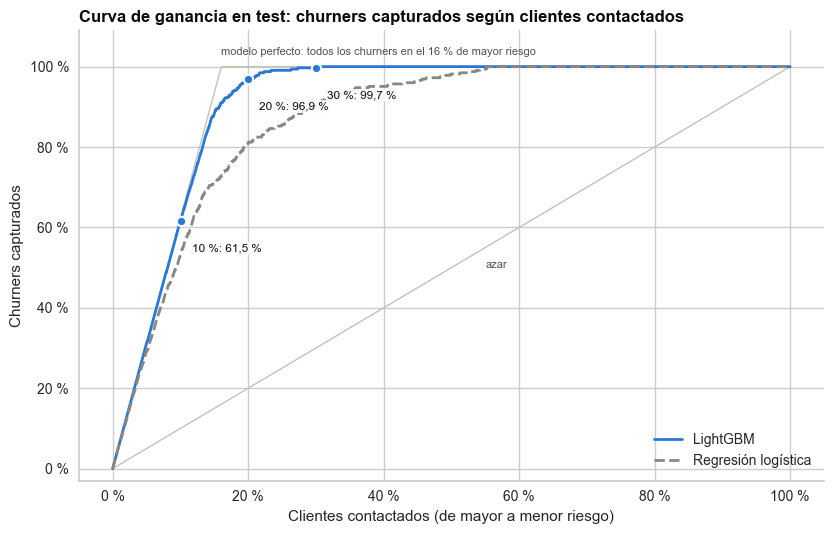

WindowsPath('C:/Users/PERSONAL/Projects/U-Analitica II/Proyecto Final Analitica II/Trabajo Juanfer & Juandi/reports/figures/negocio_01_curva_ganancia.png')

In [31]:
lectura = negocio.lectura_test(y_test, probabilidades_test[modelo_final], n_remuestras=2000)
escenarios_test, incremental_test = lectura["escenarios"], lectura["incremental"]
ic_escenarios, deciles_test = lectura["intervalos"], lectura["deciles"]
reportes.guardar_tabla(escenarios_test, "negocio_escenarios_test")
reportes.guardar_tabla(incremental_test, "negocio_incremental_test")
reportes.guardar_tabla(ic_escenarios, "negocio_ic_escenarios_test")
reportes.guardar_tabla(deciles_test, "negocio_deciles_test")
display(escenarios_test.join(ic_escenarios).round(4))  # el incremental de test se lee en los deciles 2 y 3
print("Tabla de ganancia por deciles de riesgo en test (decil 1 = 10 % de mayor riesgo):")
display(deciles_test.round(4))

fig = graficos_negocio.curvas_ganancia(
    {modelo_final: negocio.curva_ganancia(y_test, probabilidades_test[modelo_final]),
     "Regresión logística": negocio.curva_ganancia(y_test, probabilidades_test["Regresión logística"])},
    tasa_churn=float(y_test.mean()), capacidades=config.ESCENARIOS_CAPACIDAD,
    titulo="Curva de ganancia en test: churners capturados según clientes contactados",
    principal=modelo_final, referencia_gris="Regresión logística")
reportes.mostrar_figura(fig, "negocio_01_curva_ganancia")

#### Lectura y decisión (test)

- **El test confirma train:** con el 20 %, 315 de 405 contactados son churners (captura 96,92 %, IC 95 % de 94,77 % a 98,46 %; precisión 77,78 %); con el 10 %, 200 de 203; con el 30 %, 324 de 608.
- **Riesgo muy concentrado:** el decil 1 tiene 98,52 % de churn (lift 6,14), el decil 3 (el paso de 20 % a 30 %) solo 4,43 % y desde el decil 5 no hay churners.
- **El umbral implícito es muy bajo** (0,0113 en el 20 %): se **selecciona por ranking (top k %)** y no por un umbral de probabilidad (5.3).

### 5.5 Equilibrio y beneficio

**Supuestos** (no son datos del caso): capacidad de 10, 20 y 30 %; `s`, fracción de churners contactados que se quedan gracias al beneficio (0,2; 0,5 o 1,0); y `r = V / c`, cuántas veces vale un cliente retenido frente al costo del beneficio.

**Beneficio.** Con `n` contactados y `TP` churners entre ellos, el beneficio neto en unidades de costo es `TP · s · r − n`. Contactar paga si `r > 1 / (precisión · s)` (**razón de equilibrio**). Para ampliar de escenario se usa la **precisión marginal**, no la promedio.

#### Razón de equilibrio y beneficio según los supuestos

r_equilibrio_promedio             r_equilibrio_marginal              
tasa_exito                   0.2   0.5   1.0                   0.2    0.5    1.0
capacidad                                                                       
0.1                         5.07  2.03  1.01                  5.07   2.03   1.01
0.2                         6.38  2.55  1.28                  8.62   3.45   1.72
0.3                         9.38  3.75  1.88                150.00  60.00  30.00

Contacto óptimo y beneficio por cliente de la base, train fuera de pliegue:


,fraccion_optima,captura_en_optimo,beneficio_optimo_por_cliente,beneficio_por_cliente_10,beneficio_por_cliente_20,beneficio_por_cliente_30
producto_s_r,,,,,,
1.5,0.1437,0.8602,0.0637,0.0480,0.0350,-0.0600
3.0,0.1681,0.9401,0.2851,0.1959,0.2700,0.1800
10.0,0.2078,0.9839,1.3735,0.8863,1.3665,1.2998
30.0,0.2226,0.9892,4.5472,2.8589,4.4994,4.4994


Confirmación en test: fracción óptima de 14.61% a 23.40% (en train, de 14.37% a 22.26%); tabla completa en reports/tables


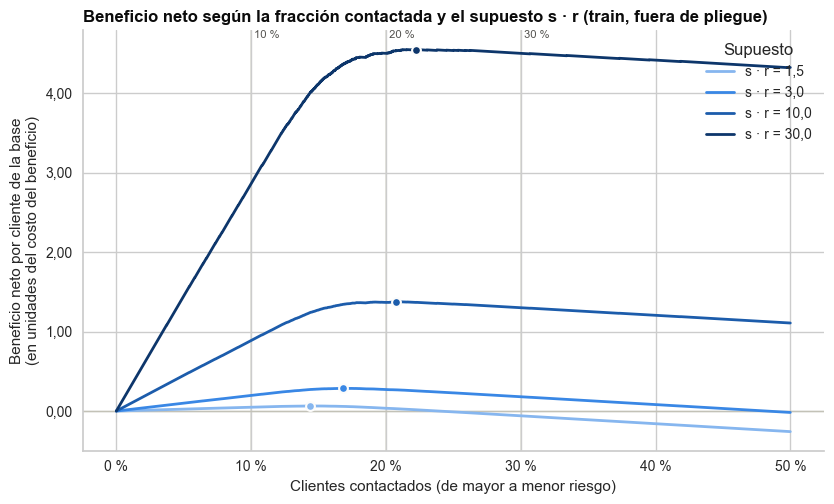

WindowsPath('C:/Users/PERSONAL/Projects/U-Analitica II/Proyecto Final Analitica II/Trabajo Juanfer & Juandi/reports/figures/negocio_02_curvas_beneficio.png')

In [32]:
equilibrio = negocio.tabla_equilibrio(escenarios_oof, incremental_oof, tasas_exito=(0.2, 0.5, 1.0))
reportes.guardar_tabla(equilibrio, "negocio_equilibrio_oof", indice=False)
display(equilibrio.pivot(index="capacidad", columns="tasa_exito",
                         values=["r_equilibrio_promedio", "r_equilibrio_marginal"]).round(2))

optimo = negocio.beneficio_optimo_por_producto({"oof": (particion.y_train, oof[modelo_final]),
                                                 "test": (y_test, probabilidades_test[modelo_final])})
optimo_oof, optimo_test = optimo["oof"], optimo["test"]
reportes.guardar_tabla(optimo_oof, "negocio_optimo_oof")
reportes.guardar_tabla(optimo_test, "negocio_optimo_test")
print("Contacto óptimo y beneficio por cliente de la base, train fuera de pliegue:")
display(optimo_oof.round(4))
print(f"Confirmación en test: fracción óptima de {optimo_test['fraccion_optima'].min():.2%} a "
      f"{optimo_test['fraccion_optima'].max():.2%} (en train, de {optimo_oof['fraccion_optima'].min():.2%} "
      f"a {optimo_oof['fraccion_optima'].max():.2%}); tabla completa en reports/tables")

fig = graficos_negocio.curvas_beneficio(
    {rs: negocio.curva_beneficio(particion.y_train, oof[modelo_final], rs) for rs in config.PRODUCTOS_SR},
    config.ESCENARIOS_CAPACIDAD,
    "Beneficio neto según la fracción contactada y el supuesto s · r (train, fuera de pliegue)")
reportes.mostrar_figura(fig, "negocio_02_curvas_beneficio")

#### Lectura y decisión

- **La recomendación depende de s · r** (tasa de éxito por valor relativo del cliente). Con s = 1, las razones de equilibrio de la tabla marcan los cortes: bajo 1,01 no paga contactar; de 1,01 a 1,72 conviene el 10 %; de 1,72 a 30, el 20 %; sobre 30, el 30 %.
- **Óptimos:** con s · r de 1,5 conviene contactar a 14,37 %; con 3, a 16,81 %; con 10, a 20,78 %; con 30, a 22,26 %. Con los mismos supuestos, el test da fracciones parecidas.

**Decisión. Si s · r está entre 1,72 y 30, contactar en cada ciclo al 20 % de mayor riesgo de la base activa:** captura 97 de cada 100 churners con un volumen de contactos apenas mayor que la tasa de churn (20 % frente a 16 %). El banco debe estimar margen, costo y tasa de éxito con un piloto (6.4).

#### Decisión sobre Montecarlo

Se aprobó incluirlo solo si aportaba a la decisión, y no aporta: la evaluación del modelo ya está validada (5.1 a 5.3), los supuestos cambian la conclusión solo a través de s · r (con puntos de corte ya calculados) y, sin datos del banco sobre s, V y c, habría que inventar las distribuciones. **Decisión (aprobada por el equipo):** no se agrega. Con rangos reales de costo, margen y éxito sería el paso natural.

### 5.6 Importancia y dependencia

La permutación se calcula en **train con los mismos 5 pliegues** y la ganancia sale del modelo ajustado con todo train; el test no se reutiliza. La importancia es **relativa y no causal**. Se usan dos medidas: **ganancia** (cuánto reduce el error cada variable en los árboles; rápida, pero premia variables con muchos valores) y **permutación** (se desordena una variable en el pliegue de validación y se mide cuánto cae el AUC; con variables correlacionadas, una cubre a la otra).

#### Importancia de variables del modelo final

,caida_auc_media,caida_auc_desv,pliegues_con_caida,importancia_ganancia_pct,ranking_permutacion,ranking_ganancia
total_trans_ct,0.1555,0.0074,5,27.2107,1,1
total_trans_amt,0.0856,0.0055,5,21.6285,2,2
total_amt_chng_q4_q1,0.0080,0.0019,5,6.5939,3,6
total_relationship_count,0.0079,0.0014,5,7.5663,4,4
total_ct_chng_q4_q1,0.0052,0.0011,5,7.4037,5,5
total_revolving_bal,0.0049,0.0006,5,13.5695,6,3
months_inactive_12_mon,0.0020,0.0004,5,2.1898,7,10
customer_age,0.0020,0.0008,5,3.2730,8,7
contacts_count_12_mon,0.0013,0.0003,5,1.4570,9,11
credit_limit,0.0012,0.0007,5,2.6832,10,8


Peso de las 4 variables de actividad transaccional en la ganancia: 62.84 %
Peso de las 5 variables sociodemográficas categóricas en la ganancia: 2.38 %


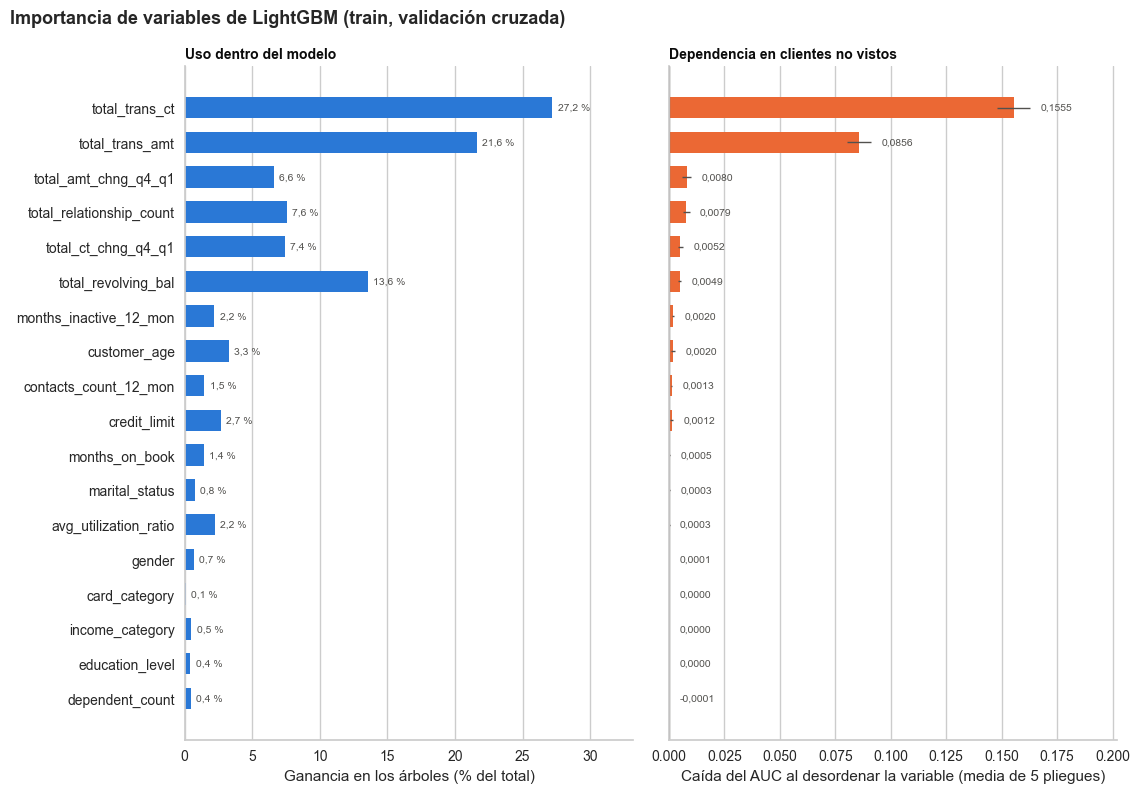

WindowsPath('C:/Users/PERSONAL/Projects/U-Analitica II/Proyecto Final Analitica II/Trabajo Juanfer & Juandi/reports/figures/explicabilidad_01_importancia.png')

In [33]:
pipeline_final = pipelines_finales[modelo_final]
importancia_ganancia = explicabilidad.importancia_ganancia(pipeline_final)
importancia_permutacion = explicabilidad.importancia_permutacion_cv(
    pipeline_final, particion.X_train, particion.y_train, cv, n_repeticiones=5)

importancia = explicabilidad.tabla_importancia(importancia_permutacion, importancia_ganancia)
reportes.guardar_tabla(importancia, "explicabilidad_importancia")
display(importancia.round(4))

actividad = ["total_trans_ct", "total_trans_amt", "total_ct_chng_q4_q1", "total_amt_chng_q4_q1"]
print(f"Peso de las 4 variables de actividad transaccional en la ganancia: {importancia_ganancia[actividad].sum():.2f} %")
print(f"Peso de las 5 variables sociodemográficas categóricas en la ganancia: "
      f"{importancia_ganancia[datos.COLUMNAS_CATEGORICAS].sum():.2f} %")

fig = graficos_negocio.importancia_variables(importancia_ganancia, importancia_permutacion,
                                             "Importancia de variables de LightGBM (train, validación cruzada)")
reportes.mostrar_figura(fig, "explicabilidad_01_importancia")

#### Lectura y decisión

- **La caída de actividad es la señal de alerta:** desordenar `total_trans_ct` y `total_trans_amt` baja el AUC en 0,1555 y 0,0856 (27,21 % y 21,63 % de la ganancia); las cuatro variables de actividad suman 62,84 %. Después, ninguna baja el AUC más de 0,01.
- **El perfil casi no cuenta:** las cinco categóricas suman 2,38 % de la ganancia; `gender` baja el AUC en 0,0001. El saldo rotativo es tercero por ganancia (13,57 %) y sexto por permutación: la utilización del cupo cubre parte de su información.

**Lectura de negocio.** Importa **cómo cambia el uso de la tarjeta**, no quién es el cliente: una señal que se puede vigilar en cada lote (no causal).

#### Dependencia parcial de las variables principales

La **dependencia parcial** da la probabilidad de churn promedio si todos los clientes tuvieran el valor *x* de una variable (percentiles 1 a 99). Se muestran una por una las variables de los puestos 3 a 8.

Variables de los puestos 3 a 8 del ranking de permutación: ['total_amt_chng_q4_q1', 'total_relationship_count', 'total_ct_chng_q4_q1', 'total_revolving_bal', 'months_inactive_12_mon', 'customer_age']
total_amt_chng_q4_q1       de     0.34 a     1.51: prob. de 20.90% a 10.42% (mín. 10.42%, máx. 20.90%)
total_relationship_count   de     1.00 a     6.00: prob. de 25.03% a 15.05% (mín. 15.05%, máx. 25.03%)
total_ct_chng_q4_q1        de     0.23 a     1.50: prob. de 18.87% a 11.56% (mín. 11.51%, máx. 18.87%)
total_revolving_bal        de     0.00 a  2517.00: prob. de 17.32% a 16.91% (mín. 13.94%, máx. 18.24%)
months_inactive_12_mon     de     0.00 a     6.00: prob. de 16.01% a 16.22% (mín. 14.23%, máx. 16.40%)
customer_age               de    27.00 a    65.00: prob. de 9.18% a 16.07% (mín. 9.18%, máx. 16.56%)


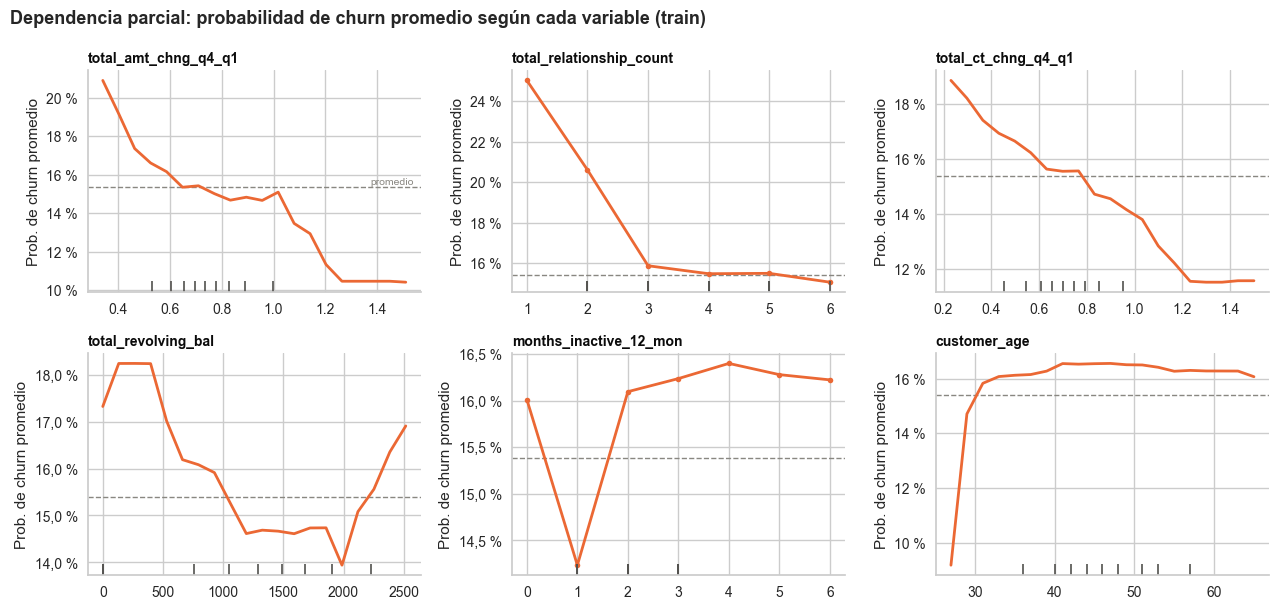

WindowsPath('C:/Users/PERSONAL/Projects/U-Analitica II/Proyecto Final Analitica II/Trabajo Juanfer & Juandi/reports/figures/explicabilidad_02_dependencia_parcial.png')

In [34]:
siguientes = list(importancia_permutacion.index[2:8])
assert not set(siguientes) & set(datos.COLUMNAS_CATEGORICAS), "la dependencia parcial 1D se dibuja solo para numéricas"
print(f"Variables de los puestos 3 a 8 del ranking de permutación: {siguientes}")
dependencias = explicabilidad.dependencia_parcial(pipeline_final, particion.X_train, siguientes, puntos=20)
reportes.guardar_tabla(pd.concat(dependencias, names=["variable", "punto"]), "explicabilidad_dependencia_parcial")
for variable, curva in dependencias.items():
    extremos = curva["prob_churn_media"]
    print(f"{variable:<26} de {curva['valor'].iloc[0]:>8.2f} a {curva['valor'].iloc[-1]:>8.2f}: "
          f"prob. de {extremos.iloc[0]:.2%} a {extremos.iloc[-1]:.2%} (mín. {extremos.min():.2%}, máx. {extremos.max():.2%})")

prob_media_train = float(oof[modelo_final].mean())
fig = graficos_negocio.dependencias_parciales(
    dependencias, particion.X_train, prob_media_train,
    "Dependencia parcial: probabilidad de churn promedio según cada variable (train)")
reportes.mostrar_figura(fig, "explicabilidad_02_dependencia_parcial")

#### Mapa conjunto de monto y transacciones

`total_trans_ct` y `total_trans_amt` están muy correlacionadas (0,88): moverlas por separado crea clientes inexistentes, así que se analizan **juntas**, dejando en blanco las celdas con menos de 10 clientes (promedio sobre 2.000 clientes de train).

Celdas con al menos 10 clientes: 74 de 256, con 7,856 de 8,101 clientes de train
Rango de la probabilidad promedio por tramo de monto del EDA (solo celdas con datos):


,celdas,prob_min,prob_max,clientes
total_trans_amt,,,,
hasta 3.000,21,0.0027,0.6487,3407
3.001 a 6.000,18,0.0003,0.4074,3465
6.001 a 11.000,18,0.0042,0.7772,492
más de 11.000,17,0.0010,0.0266,492


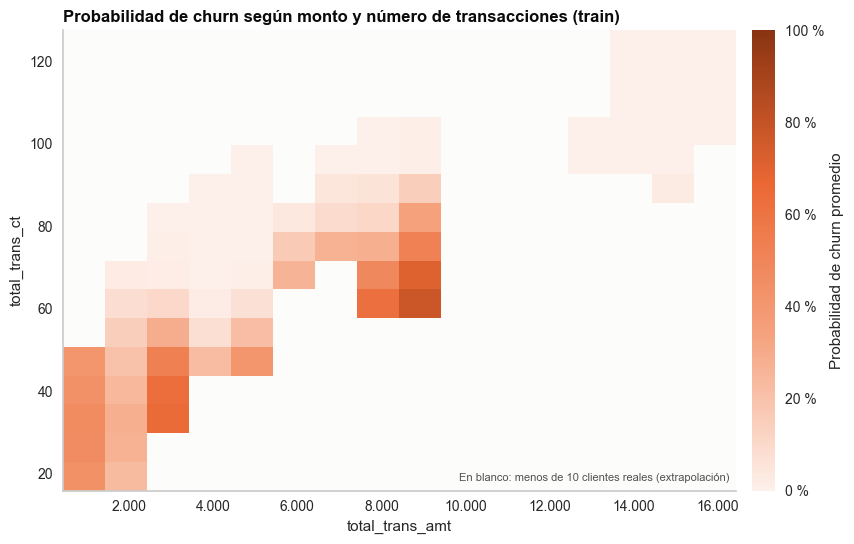

WindowsPath('C:/Users/PERSONAL/Projects/U-Analitica II/Proyecto Final Analitica II/Trabajo Juanfer & Juandi/reports/figures/explicabilidad_03_monto_frecuencia.png')

In [35]:
conjunta = explicabilidad.dependencia_parcial_2d(pipeline_final, particion.X_train, "total_trans_amt", "total_trans_ct",
                                                 puntos=16, muestra=2000)
reportes.guardar_tabla(conjunta, "explicabilidad_monto_frecuencia", indice=False)
con_datos, resumen_tramos = explicabilidad.resumir_tramos(conjunta)
reportes.guardar_tabla(resumen_tramos, "explicabilidad_monto_frecuencia_tramos")
print(f"Celdas con al menos 10 clientes: {len(con_datos)} de {len(conjunta)}, "
      f"con {con_datos['clientes_en_celda'].sum():,} de {len(particion.X_train):,} clientes de train")
print("Rango de la probabilidad promedio por tramo de monto del EDA (solo celdas con datos):")
display(resumen_tramos.round(4))

fig = graficos_negocio.dependencia_parcial_conjunta(conjunta, "total_trans_amt", "total_trans_ct",
                                                    "Probabilidad de churn según monto y número de transacciones (train)")
reportes.mostrar_figura(fig, "explicabilidad_03_monto_frecuencia")

#### Lectura y decisión

- **El mapa explica los segmentos del EDA:** a igual monto, el modelo asigna mucho más riesgo a quien hace menos transacciones (monto cercano a 8.927: de 77,72 % con 61 transacciones a 0,89 % con 96) y sobre 11.000 ninguna celda con datos supera 2,66 %. Solo se leen las 74 de 256 celdas con 10 o más clientes (7.856 de 8.101).
- **Las demás variables mueven poco la probabilidad promedio:** los cambios entre trimestres la bajan de 20,90 % a 10,42 % (monto) y de 18,87 % a 11,56 % (transacciones); un solo producto la sube a 25,03 %; el saldo y la inactividad casi no la mueven.
- **Edad:** 9,18 % a los 27 años y 15,83 % a 16,56 % desde los 31; variable sensible (5.8).

### 5.7 Sensibilidad y equidad

Se reentrena el **mismo pipeline** quitando variables y se compara el AUC pliegue a pliegue y el escenario de 20 %:

| Variante | Riesgo que evalúa |
|---|---|
| Sin contactos | **Fuga temporal:** que la variable incluya llamadas del propio retiro |
| Sin sexo | **Sesgo** por decidir con el sexo del cliente |
| Sin sexo ni ingresos | Los ingresos como **sustituto del sexo** |
| Sin sexo ni contactos | Los dos riesgos a la vez |

#### Sensibilidad a variables riesgosas

In [36]:
sensibilidad, oof_variantes = explicabilidad.sensibilidad_variables(
    pipeline_final, particion.X_train, particion.y_train, cv, explicabilidad.VARIANTES_SENSIBILIDAD)

# Control: la variante completa debe reproducir exactamente las predicciones fuera de pliegue de 5.1
diferencia_control = np.abs(oof_variantes["completo"] - oof[modelo_final]).max()
assert diferencia_control < 1e-12, diferencia_control
print(f"Control: la variante completa reproduce las predicciones de 5.1 (diferencia máxima {diferencia_control:.1e})")

sensibilidad = explicabilidad.agregar_escenarios(sensibilidad, particion.y_train, oof_variantes)
reportes.guardar_tabla(sensibilidad, "explicabilidad_sensibilidad")
display(sensibilidad.round(5))

Control: la variante completa reproduce las predicciones de 5.1 (diferencia máxima 0.0e+00)


,variables_quitadas,auc_cv,auc_cv_desv,diferencia_vs_completo,diferencia_desv,pliegues_por_debajo,churners_10,captura_10,precision_10,churners_20,captura_20,precision_20
variante,,,,,,,,,,,,
completo,ninguna,0.99415,0.00114,0.00000,0.00000,0,799.0,0.61367,0.98642,1269.0,0.97465,0.78333
sin contactos,contacts_count_12_mon,0.99360,0.00148,-0.00055,0.00055,4,798.0,0.61290,0.98519,1268.0,0.97389,0.78272
sin sexo,gender,0.99413,0.00113,-0.00002,0.00020,2,799.0,0.61367,0.98642,1272.0,0.97696,0.78519
sin sexo ni ingresos,"gender, income_category",0.99390,0.00114,-0.00024,0.00017,5,799.0,0.61367,0.98642,1271.0,0.97619,0.78457
sin sexo ni contactos,"gender, contacts_count_12_mon",0.99352,0.00132,-0.00063,0.00039,4,799.0,0.61367,0.98642,1272.0,0.97696,0.78519


#### Los 42 clientes con 6 contactos

In [37]:
seis_contactos = particion.X_train["contacts_count_12_mon"] == 6
grupo_seis = explicabilidad.seleccion_en_grupo(
    particion.y_train, {k: oof_variantes[k] for k in ("completo", "sin contactos")}, seis_contactos, capacidad=0.2)
reportes.guardar_tabla(grupo_seis, "explicabilidad_seis_contactos")
display(grupo_seis.round(4))

,clientes,churners,prob_media,prob_minima,dentro_del_escenario
variante,,,,,
completo,42,42,0.9563,0.0031,41
sin contactos,42,42,0.8568,0.0001,40


#### Lectura y decisión

- **Posible fuga en `contacts_count_12_mon`:** quitarla cuesta 0,00055 de AUC (de 0,99415 a 0,99360; más bajo en 4 de 5 pliegues) y 1 churner con el 20 %. De los 42 clientes con 6 contactos, 40 siguen dentro del 20 % sin ella: el modelo no depende de esa regla y la cifra principal no se infla por esta variable.
- **Sexo y sustituto:** quitar `gender` cuesta 0,00002; quitar también ingresos, 0,00024. La versión **sin sexo ni contactos** pierde 0,00063 de AUC sin perder churners capturados con el 20 % (6.1).

**Decisión.** El modelo completo evaluado en 5.1 sigue siendo el **resultado oficial** (cambiarlo exigiría reutilizar el test). Para **producción** se usa la variante **sin `gender` ni `contacts_count_12_mon`**, que rinde igual, deja de usar el sexo del cliente y evita la posible fuga de contactos (aprobada por el equipo; 6.1 la construye).

#### Trato por sexo y por edad en el escenario de 20 %

Que el modelo casi no use `gender` no garantiza un trato igual. Por grupo se revisa qué parte se contacta, qué captura, precisión y **falsas alarmas** (clientes que no se iban y reciben el beneficio) logra y qué tan bien ordena el modelo a sus clientes (**AUC dentro del grupo**), con el criterio de **proporcionalidad al riesgo real**: `razon_contacto_riesgo` es el porcentaje contactado dividido por la tasa real de churn del grupo. Se revisan el sexo y cuatro tramos de edad, en el escenario de 20 % y con predicciones fuera de pliegue en train; no es una auditoría completa de equidad.

In [38]:
equidad = pd.concat({nombre: explicabilidad.equidad_por_grupo(particion.y_train, oof_variantes[nombre],
                                                              particion.X_train["gender"], capacidad=0.2)
                     for nombre in ("completo", "sin sexo", "sin sexo ni ingresos", "sin sexo ni contactos")},
                    names=["variante", "grupo"])
equidad["razon_contacto_riesgo"] = equidad["pct_contactado"] / equidad["tasa_churn_real"]
reportes.guardar_tabla(equidad, "explicabilidad_equidad_sexo")
display(equidad.round(4))

brecha_sexo = explicabilidad.ic_brecha_captura(particion.y_train, oof_variantes["completo"], particion.X_train["gender"],
                                               capacidad=0.2, n_remuestras=2000, semilla=config.SEMILLA)
reportes.guardar_tabla(brecha_sexo, "explicabilidad_brecha_captura_sexo")
display(brecha_sexo.round(4))

tramo_edad = exploracion.tramos(particion.X_train["customer_age"], *explicabilidad.TRAMOS_EDAD)
equidad_edad = pd.concat({nombre: explicabilidad.equidad_por_grupo(particion.y_train, oof_variantes[nombre], tramo_edad,
                                                                   capacidad=0.2).loc[explicabilidad.TRAMOS_EDAD[1]]
                          for nombre in ("completo", "sin sexo ni contactos")}, names=["variante", "grupo"])
equidad_edad["razon_contacto_riesgo"] = equidad_edad["pct_contactado"] / equidad_edad["tasa_churn_real"]
reportes.guardar_tabla(equidad_edad, "explicabilidad_equidad_edad")
print("Trato por tramo de edad (años) en el escenario de 20 %:")
display(equidad_edad.round(4))

clientes  tasa_churn_real  pct_contactado  captura_en_grupo  precision_en_grupo  falsas_alarmas_en_grupo  auc_en_grupo  \
variante              grupo                                                                                                                           
completo              F          4272           0.1753          0.2083            0.9853              0.8292                   0.0431        0.9963   
                      M          3829           0.1444          0.1907            0.9602              0.7274                   0.0607        0.9908   
sin sexo              F          4272           0.1753          0.2079            0.9853              0.8311                   0.0426        0.9962   
                      M          3829           0.1444          0.1912            0.9656              0.7295                   0.0604        0.9908   
sin sexo ni ingresos  F          4272           0.1753          0.2067            0.9840              0.8347                   0.0414        0.9962   
                      M          3829           0.1444          0.1925            0.9656              0.7246                   0.0620        0.9903   
sin sexo ni contactos F          4272           0.1753          0.2079            0.9880              0.8333                   0.0420        0.9959   
                      M          3829           0.1444          0.1912            0.9620              0.7268                   0.0611        0.9897   

                             prob_media_predicha  razon_contacto_riesgo  
variante              grupo                                              
completo              F                   0.1699                 1.1883  
                      M                   0.1361                 1.3201  
sin sexo              F                   0.1681                 1.1856  
                      M                   0.1372                 1.3237  
sin sexo ni ingresos  F                   0.1667                 1.1789  
                      M                   0.1387                 1.3327  
sin sexo ni contactos F                   0.1677                 1.1856  
                      M                   0.1379                 1.3237

,churners_F,churners_M,brecha_captura,ic95_inf,ic95_sup,incluye_cero
comparacion,,,,,,
F menos M,749,553,0.0251,0.0079,0.0437,False


Trato por tramo de edad (años) en el escenario de 20 %:


clientes  tasa_churn_real  pct_contactado  captura_en_grupo  precision_en_grupo  falsas_alarmas_en_grupo  auc_en_grupo  \
variante              grupo                                                                                                                               
completo              hasta 35        720           0.1250          0.1611            0.9778              0.7586                   0.0444        0.9921   
                      36 a 45        2974           0.1644          0.2078            0.9755              0.7718                   0.0567        0.9942   
                      46 a 55        3320           0.1675          0.2042            0.9730              0.7979                   0.0496        0.9943   
                      más de 55      1087           0.1536          0.1914            0.9760              0.7837                   0.0489        0.9940   
sin sexo ni contactos hasta 35        720           0.1250          0.1583            0.9778              0.7719                   0.0413        0.9891   
                      36 a 45        2974           0.1644          0.2071            0.9775              0.7760                   0.0555        0.9939   
                      46 a 55        3320           0.1675          0.2048            0.9766              0.7985                   0.0496        0.9934   
                      más de 55      1087           0.1536          0.1932            0.9760              0.7762                   0.0511        0.9941   

                                 prob_media_predicha  razon_contacto_riesgo  
variante              grupo                                                  
completo              hasta 35                0.1095                 1.2889  
                      36 a 45                 0.1577                 1.2638  
                      46 a 55                 0.1620                 1.2194  
                      más de 55               0.1479                 1.2455  
sin sexo ni contactos hasta 35                0.1086                 1.2667  
                      36 a 45                 0.1570                 1.2597  
                      46 a 55                 0.1622                 1.2230  
                      más de 55               0.1480                 1.2575

#### Lectura y decisión (escenario de 20 %, train fuera de pliegue)

- **Captura:** 98,53 % en mujeres y 96,02 % en hombres. La brecha de 2,51 puntos tiene un IC 95 % de 0,79 a 4,37 (749 y 553 churners): es real, aunque pequeña (unos 14 churners hombres), y casi no cambia sin `gender` ni contactos (2,60).
- **No viene de contactar menos a los hombres:** se les contacta más en proporción a su riesgo (razón de 1,32 frente a 1,19), pero el modelo distingue peor a sus churners. Su precisión es menor (72,74 % frente a 82,92 %), en parte porque su tasa de churn es más baja (14,44 % frente a 17,53 %).
- **Calidad del orden por grupo:** el AUC es de 0,9963 en mujeres y 0,9908 en hombres, y las falsas alarmas son de 4,31 % y 6,07 %. Por edad, el desempeño es parejo: AUC de 0,9921 a 0,9943, captura de 97,30 % a 97,78 % y contacto proporcional al riesgo en los cuatro tramos (razón de 1,22 a 1,29).

**Lectura de negocio.** La brecha no depende de que el modelo use `gender`, y su causa no se puede atribuir con estos datos (sexo e ingresos no son independientes, 2.9). Se vigila en el monitoreo; no se sacan conclusiones comerciales por sexo.

### 5.8 Riesgos y limitaciones

| Riesgo | Evidencia | Mitigación |
|---|---|---|
| Momento de medición de las variables | AUC de 0,99 con variables de 2021 y retiro medido al cierre de 2022; 42 de 42 con 6 contactos se fueron (2.6) | Confirmar con el banco que la actividad se mide antes del retiro; si no, el desempeño real sería menor |
| Posible fuga en `contacts_count_12_mon` | El caso la define como contactos "en el último año", sin decir quién los inicia ni si incluyen el trámite de retiro; quitarla cuesta 0,00055 de AUC (5.7) | En producción, la variante sin ella; confirmar la definición con el banco |
| Diferencias de desempeño por sexo | Captura 2,51 puntos menor en hombres (IC 95 % de 0,79 a 4,37), con y sin `gender` (5.7) | Quitar `gender` evita decidir con el sexo, pero no cierra la brecha: vigilarla en el monitoreo y revisar su origen con el banco |
| Uso de la edad | Menor riesgo en los más jóvenes (5.6); desempeño parejo entre tramos de edad (5.7) | Validar con cumplimiento |
| Artefactos del archivo | Sexo e ingresos; pico de 36 meses (2.9) | Pesan poco (2,38 % de la ganancia); revisar la captura de datos |
| Probabilidad intermedia subestimada | 5.3 | Seleccionar por ranking |
| Predice quién se va, no quién responde | 5.4 | Piloto con grupo de control |
| Validación en el mismo período | Partición aleatoria de una sola foto: train y test son clientes del mismo período (variables de 2021, churn al cierre de 2022) | El AUC de test no demuestra el desempeño con clientes de años futuros: es una estimación optimista para ellos. Confirmarlo con la captura del grupo de control en el primer ciclo real (6.3) y, cuando haya fechas, con una partición temporal |
| Importancia no causal | 5.6 | Probar las intervenciones antes de diseñarlas |
| Supuestos y simulaciones | Capacidades, `s` y `r` son supuestos (5.5); los lotes de 6.2 y 6.3 son clientes de train, alterados a propósito en 6.3 | Las cifras económicas son condicionales a los supuestos; las de 6.2 y 6.3 muestran la mecánica, no el desempeño |

### 5.9 Conclusiones y decisión

1. **El modelo elegido es LightGBM:** AUC de 0,9933 en test (IC 95 % de 0,9906 a 0,9957), a 0,0008 de la CV. Se midió con clientes del mismo período, no de años futuros (5.8). XGBoost y Gradient Boosting no se distinguen de él (5.2); la logística (0,9445) es peor de forma significativa.
2. **Con el 20 % de contacto captura 315 de los 325 churners de test** (96,92 %; precisión de 77,78 %) (5.4).
3. **Recomendación:** si s · r está entre 1,72 y 30, contactar en cada ciclo al 20 % de mayor riesgo de la base activa, por ranking (5.5).
4. **Qué usa el modelo:** el comportamiento, no el perfil. La actividad transaccional suma 62,84 % de la ganancia y el perfil, 2,38 % (5.6).
5. **Producción:** el candidato sin `contacts_count_12_mon` ni `gender` deja de usar el sexo y la variable de posible fuga sin perder churners capturados; el oficial sigue siendo el evaluado en test (6.1).

Los riesgos y limitaciones quedan en 5.8.

## CRISP-DM Fase 6: Despliegue, monitoreo y control

### 6.1 Modelo viable

Un modelo es viable si se usa fuera del notebook con los mismos resultados y con controles que eviten puntuar datos rotos. Se guardan dos, con papeles distintos:

| | Modelo oficial | Candidato de producción |
|---|---|---|
| Qué es | LightGBM completo (Fase 4) | El mismo LightGBM sin `gender` ni `contacts_count_12_mon` |
| Evidencia | **Test**, una sola vez (5.1) | **Solo CV en train**; no se evalúa en test |
| Uso | Resultado oficial | Puntuar clientes en la operación |
| Archivo | `models/modelo_oficial.joblib` | `models/modelo_produccion.joblib` |

Ambos se entrenan con los mismos 8.101 clientes de train. Los hiperparámetros quedan fijos en `churn.produccion.HIPERPARAMETROS_OFICIALES` (`python -m churn.produccion entrenar` los reconstruye en segundos) y cada archivo guarda su ficha: papel, evaluación, columnas, hiperparámetros, métricas con su origen, huella de datos y versiones.

#### Evidencia del candidato de producción

In [39]:
metricas_produccion, oof_produccion = produccion.evidencia_cv_produccion(pipeline_final, particion.X_train, particion.y_train)

# Controles: el oficial reproduce las predicciones de 5.1 y el candidato las de la variante de 5.7
control_oficial = np.abs(oof_produccion["oficial"] - oof[modelo_final]).max()
control_variante = np.abs(oof_produccion["produccion"] - oof_variantes["sin sexo ni contactos"]).max()
print(f"Oficial frente a 5.1: diferencia máxima {control_oficial:.1e}")
print(f"Candidato (variables quitadas) frente a la variante de 5.7 (variables neutralizadas): diferencia máxima {control_variante:.1e}")

escenarios_cv = pd.concat({"oficial": negocio.tabla_escenarios(particion.y_train, oof_produccion["oficial"]),
                           "candidato de producción": negocio.tabla_escenarios(particion.y_train, oof_produccion["produccion"])},
                          names=["modelo", "capacidad"])
ap_oficial = evaluacion.calcular_metricas(particion.y_train, oof_produccion["oficial"])["ap"]
evidencia = produccion.tabla_evidencia_cv(metricas_produccion, ap_oficial, escenarios_cv)
reportes.guardar_tabla(evidencia, "modelo_viable_cv")
reportes.guardar_tabla(escenarios_cv, "modelo_viable_escenarios_cv")
display(evidencia.round(5))
print(f"Diferencia pareada de AUC (candidato - oficial): {metricas_produccion['diferencia_auc_vs_oficial']:.5f} "
      f"(desv. {metricas_produccion['diferencia_desv']:.5f}; más baja en {metricas_produccion['pliegues_por_debajo']} de 5 pliegues)")
print(f"Resultado oficial en test (5.1, solo modelo oficial): AUC {metricas_05.loc[modelo_final, 'auc']:.4f}")

Oficial frente a 5.1: diferencia máxima 0.0e+00
Candidato (variables quitadas) frente a la variante de 5.7 (variables neutralizadas): diferencia máxima 0.0e+00


,auc_cv,ap_cv_oof,churners_20,captura_20,origen
oficial,0.99415,0.97337,1269,0.97465,validación cruzada en train
candidato de producción,0.99352,0.97086,1272,0.97696,validación cruzada en train


Diferencia pareada de AUC (candidato - oficial): -0.00063 (desv. 0.00039; más baja en 4 de 5 pliegues)
Resultado oficial en test (5.1, solo modelo oficial): AUC 0.9933


#### Entrenamiento y guardado de los dos modelos

In [40]:
artefactos = produccion.generar_modelos(particion.X_train, particion.y_train, pipeline_oficial=pipeline_final,
                                        metricas_produccion=metricas_produccion)
for rol, ruta in {"oficial": produccion.RUTA_MODELO_OFICIAL, "produccion": produccion.RUTA_MODELO_PRODUCCION}.items():
    print(f"{rol}: {ruta.relative_to(config.RAIZ).as_posix()} ({ruta.stat().st_size / 1e6:.1f} MB)")

fichas = pd.concat([produccion.ficha(a) for a in artefactos.values()], axis=1)
reportes.guardar_tabla(fichas, "modelo_viable_fichas", decimales=None)  # la ficha completa queda en reports/tables

oficial: models/modelo_oficial.joblib (3.5 MB)
produccion: models/modelo_produccion.joblib (3.5 MB)


WindowsPath('C:/Users/PERSONAL/Projects/U-Analitica II/Proyecto Final Analitica II/Trabajo Juanfer & Juandi/reports/tables/modelo_viable_fichas.csv')

#### Validaciones del modelo viable

In [41]:
oficial_cargado = produccion.cargar_modelo(produccion.RUTA_MODELO_OFICIAL)
produccion_cargado = produccion.cargar_modelo(produccion.RUTA_MODELO_PRODUCCION)
controles = produccion.controles_modelo_viable(oficial_cargado, produccion_cargado, pipeline_final,
                                               particion.X_train, particion.y_train)  # solo train: el test no se reutiliza
display(controles)
assert controles["cumple"].all(), controles

,control,cumple
0,Hiperparámetros fijos = los elegidos por la búsqueda,True
1,Oficial guardado = modelo evaluado en test (predicciones en train),True
2,Oficial reconstruido sin caché = modelo evaluado en test,True
3,Candidato reconstruido sin caché = candidato guardado,True
4,El candidato no recibe gender ni contacts_count_12_mon,True
5,"Clase positiva = Attrited Customer (código 1, columna de classes_)",True
6,Huella de los datos de train igual en ambos modelos,True
7,Candidato marcado como no evaluado en test y sin métricas de test,True


#### Lectura y decisión

- **Quitar las dos variables cuesta 0,00063 de AUC** (desviación 0,00039; más baja en 4 de 5 pliegues) y no reduce los churners capturados con el 20 % (1.272 frente a 1.269 de 1.302).
- **El único resultado de test es el del oficial** (AUC 0,9933). El candidato lo declara en su ficha (`evaluado_en_test = False`): se espera un desempeño muy parecido, pero es una expectativa, no una medición.
- **Controles superados:** lo guardado coincide con lo evaluado y con lo reconstruido sin caché, y ambos modelos comparten la huella de datos de train.

### 6.2 Uso: puntuar clientes

`puntuar_clientes` recibe clientes en el formato del banco y entrega la lista priorizada (`contactar` marca el 20 % de mayor riesgo del lote, que debe ser la base activa completa del ciclo). Rechaza columnas faltantes, vacíos, identificadores repetidos, textos en columnas numéricas, valores imposibles y categorías nuevas.

#### Puntuar un lote de ejemplo con `puntuar_clientes`

In [42]:
# Lote simulado: 20 clientes de train tomados del Excel crudo, sin la columna del objetivo.
# Traen gender y contacts_count_12_mon: el candidato las ignora.
lote_ejemplo = crudo[crudo[datos.COLUMNA_ID].isin(particion.X_train.index)].sample(20, random_state=config.SEMILLA)
lote_ejemplo = lote_ejemplo.drop(columns=config.OBJETIVO)

lista = produccion.puntuar_clientes(lote_ejemplo, produccion_cargado, capacidad=0.2)
display(lista.round(4))
print(f"Modelo: {lista.attrs['modelo']}")
print(f"Columnas ignoradas: {lista.attrs['columnas_ignoradas']}")
print(f"Contactar (20 % de {len(lista)}): {int(lista['contactar'].sum())} clientes")
assert lista["prob_churn"].is_monotonic_decreasing and list(lista["prioridad"]) == list(range(1, len(lista) + 1))

print("Ejemplo de control: un archivo sin total_trans_ct se rechaza antes de puntuar")
try:
    produccion.puntuar_clientes(lote_ejemplo.drop(columns="total_trans_ct"), produccion_cargado)
except datos.ErrorDeDatos as error:
    print(f"ErrorDeDatos: {error}")

,prioridad,prob_churn,percentil_riesgo,contactar
clientnum,,,,
815315058,1,1.0000,0.05,True
779848383,2,0.9996,0.10,True
713822208,3,0.9993,0.15,True
713041683,4,0.9975,0.20,True
827108583,5,0.0018,0.25,False
721498008,6,0.0003,0.30,False
716181858,7,0.0003,0.35,False
711210633,8,0.0002,0.40,False
780662133,9,0.0001,0.45,False


Modelo: LightGBM sin gender ni contacts_count_12_mon (candidato de producción)
Columnas ignoradas: ['gender', 'contacts_count_12_mon']
Contactar (20 % de 20): 4 clientes
Ejemplo de control: un archivo sin total_trans_ct se rechaza antes de puntuar
ErrorDeDatos: Faltan columnas que el modelo necesita: ['total_trans_ct']


#### Lectura y decisión

- Los 20 clientes de ejemplo son de train: sus probabilidades son de entrenamiento y solo muestran el formato. Un archivo sin `total_trans_ct` se rechaza antes de puntuar (reglas probadas en `tests/test_produccion.py`).
- **Uso:** contactar a los marcados en orden de `prioridad`, sin usar `prob_churn` como umbral fijo (5.3).

Fuera del notebook (desde la raíz, con el entorno activado):

```python
from churn import produccion

modelo = produccion.cargar_modelo()                           # candidato de producción
lista = produccion.puntuar_clientes(clientes, modelo, capacidad=0.2)
```

o `python -m churn.produccion puntuar clientes.xlsx lista.csv --capacidad 0.2`. Si faltan los `.joblib`, `python -m churn.produccion entrenar` los genera en segundos.

### 6.3 Monitoreo y control

Tres indicadores con semáforo, calculados por `churn.monitoreo`:

| Indicador | Qué detecta | Cuándo | Verde / amarillo / rojo | Acción en rojo |
|---|---|---|---|---|
| **PSI por variable** | Cambio en la distribución de una variable (*data drift*) | Cada lote | < 0,10 / 0,10 a 0,25 / ≥ 0,25 | Pausar la lista y revisar el dato con el banco |
| **PSI del puntaje** | Cambio en la probabilidad del modelo; resume cambios conjuntos entre variables | Cada lote | < 0,10 / 0,10 a 0,25 / ≥ 0,25 | Igual |
| **Captura del 20 %** en un grupo de control | Cambio en la relación entre variables y churn (*concept drift*), frente a la base de CV (97,70 %) | Una vez al año (el churn se conoce al cierre del año siguiente) | caída < 2 / 2 a 5 / ≥ 5 pp | Reentrenar y comparar |

La captura se mide en un **grupo de control** (alto riesgo sin beneficio): en los contactados, una campaña que funciona reduce el churn y haría parecer que el modelo empeoró. Los umbrales del PSI son la convención de la industria; los de captura, **supuestos del equipo** (`config.UMBRALES_MONITOREO`). El archivo no trae fechas: aquí se demuestra la mecánica.

#### Demostración con un lote degradado

In [43]:
modelo_uso, columnas = produccion_cargado["pipeline"], produccion_cargado["columnas_entrada"]
base = escenarios_cv.loc[("candidato de producción", 0.2), "captura"]  # línea base: CV en train
lote = particion.X_train.sample(1500, random_state=config.SEMILLA)  # lote simulado con clientes de train
# Actividad barajada: monto y número de transacciones se reordenan entre los clientes del lote (con la
# misma permutación): cada distribución queda igual, pero la actividad ya no corresponde a su cliente
barajado = lote.assign(**{c: np.random.default_rng(config.SEMILLA).permutation(lote[c]) for c in ("total_trans_ct", "total_trans_amt")})
lotes = {"sin cambios": lote, "montos +20 %": lote.assign(total_trans_amt=lote["total_trans_amt"] * 1.2), "actividad barajada": barajado}

semaforos = monitoreo.tabla_semaforos(modelo_uso, columnas, particion.X_train, lotes, captura_base=base,
                                      y_lotes={nombre: particion.y_train.loc[X.index] for nombre, X in lotes.items()})
reportes.guardar_tabla(semaforos, "monitoreo_semaforos")
display(semaforos.round(4))

,variable con más PSI,PSI variable,estado,PSI puntaje,estado puntaje,captura 20 %,caída,estado captura
sin cambios,avg_utilization_ratio,0.01385,verde,0.006682,verde,1.0,-0.023041,verde
montos +20 %,total_trans_amt,0.467642,rojo,0.172943,amarillo,0.990654,-0.013696,verde
actividad barajada,avg_utilization_ratio,0.01385,verde,0.277393,rojo,0.439252,0.537706,rojo


#### Lectura y decisión

- **Sin cambios:** los tres indicadores en verde (PSI del puntaje de 0,0067).
- **Montos +20 %:** el PSI de `total_trans_amt` pasa a rojo (0,4676) y el del puntaje a amarillo (0,1729), mientras la captura sigue en verde: los PSI avisan **antes** de conocer el churn real.
- **Actividad barajada:** monto y número de transacciones se reordenan entre clientes: cada variable conserva su distribución (PSI por variable en verde), pero la actividad ya no corresponde a cada cliente. El PSI del puntaje lo detecta sin esperar el churn (0,2774, rojo) y la captura cae a rojo (43,93 %). Por eso se vigilan los tres.

Es una simulación con clientes de train (la captura sale optimista): muestra cómo funciona el control, no un resultado del modelo.

### 6.4 Próximos pasos y oportunidades de mejora

1. **Piloto con grupo de control** dentro del 20 % de mayor riesgo, por deciles, para medir la tasa de éxito `s` (puede ser menor en el decil 1). Ese mismo grupo sirve para medir la captura de 6.3.
2. Estimar el **margen de un cliente retenido (V) y el costo del beneficio (c)**: con s · r, 5.5 da el escenario óptimo.
3. **Activar el monitoreo de 6.3** con datos reales: los dos PSI con cada lote y la captura una vez al año. Un PSI en rojo pausa la lista hasta revisar el dato; una captura en rojo obliga a reentrenar y comparar.
4. Confirmar cuándo se miden la actividad y los contactos (antes o durante el retiro) y si los contactos incluyen el trámite de retiro; validar con cumplimiento el uso de la edad.

**Oportunidades de mejora:**

- **Calibración isotónica** dentro de train, para leer la probabilidad como porcentaje literal (5.3).
- **Uplift** (efecto incremental del beneficio): con los datos del piloto, priorizar a quien cambia de decisión gracias a la oferta.
- **Análisis de supervivencia** (tiempo hasta el retiro), cuando haya fechas.
- **Deriva multivariada** con un clasificador que distinga lotes nuevos de train, como complemento de los PSI.